# 25 - Betting strategies (P8-03, P8-04, P8-05)

Betting every game at average odds loses 2.8%. This notebook tests selective
strategies. **P8-03** (this section): bet only the picks the model is most
confident about. **P8-04** (below P8-03's findings): value betting and staking.
**P8-05** (below P8-04's findings): accumulators and system bets vs singles on the same legs.

P8-02 found the model has no information beyond the price (log loss +0.021 vs the
market in every league-season; blend weight on the model 0). So the prior here is
that no confidence rule makes money; this section documents that properly.

- **Data:** `data/processed/oos_predictions.csv` (P8-01), 7 domestic leagues.
- **Bet:** 1 unit on the model's argmax pick (the live bet), at opening odds.
  `avg` = market average (default), `max` = best price (optimistic bound), `b365` = one real bookmaker (added for P8-07;
  the findings below quote avg and max).
- **Split:** rules are tuned on **22-23/23-24**, reported on **24-25/25-26**, then
  shown on 26-27 to date.
- **Uncertainty:** ROI 95% CI from resampling betting weeks (5,000, seed 42),
  `betting.simulate.bootstrap_roi`.
- **Multiple testing:** every variant below is written to
  `data/processed/betting_variants.csv` for P8-07.

**Selection rule, fixed before any results were computed:** among all P8-03
variants, at `avg` odds in the tuning seasons, with at least 150 tuning bets
(about 1.7 a week), the one with the highest ROI. Ties go to more bets. Its
report-season result is recorded whatever it is.

In [1]:
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from betting.market import prices
from betting.simulate import bootstrap_roi, flat_argmax, load_oos, simulate, single, summarise
from betting.variants import log_variants

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)

TEST = ["22-23", "23-24", "24-25", "25-26"]
TUNE, REPORT = TEST[:2], TEST[2:]
CURRENT = "26-27"
PERIODS = {"tune": TUNE, "report": REPORT, "26-27": [CURRENT]}
OUTCOMES = ["H", "D", "A"]
SOURCES = ["avg", "b365", "max"]  # b365 added for P8-07
MIN_TUNE_BETS = 150

# Chart colours: tuning seasons = categorical slot 1, report seasons = slot 2
TUNE_COLOUR, REPORT_COLOUR = "#2a78d6", "#eb6834"

## Data

Matches are put in the simulator's order (kick-off, league, home team) so the
bootstrap resamples the same weeks in the same order as `simulate()`.
`conf` is the model's probability for its pick; `ratio` = `conf / q` where `q`
is the de-margined market probability of the same outcome (Pinnacle opening,
Avg fallback).

In [2]:
oos = load_oos()
oos = oos[oos["FTR"].notna()]
oos = oos.sort_values(["MatchDateTime", "Div", "HomeTeam"], kind="stable").reset_index(drop=True)
oos["Week"] = oos["Season"] + "|" + oos["BetWeek"]

# Argmax in A, D, H order, as backtest.py / flat_argmax break ties
proba = oos[["pA", "pD", "pH"]].to_numpy()
oos["pick"] = np.array(["A", "D", "H"])[proba.argmax(axis=1)]
oos["conf"] = proba.max(axis=1)
oos["q_pick"] = np.select([oos["pick"] == "H", oos["pick"] == "D"], [oos["qH"], oos["qD"]], oos["qA"])
oos["ratio"] = oos["conf"] / oos["q_pick"]
WON = (oos["FTR"] == oos["pick"]).to_numpy()

# Opening / closing price of the pick, per source
ODDS, CLOSE, PROFIT = {}, {}, {}
for source in SOURCES:
    opening, closing = np.full(len(oos), np.nan), np.full(len(oos), np.nan)
    for sel in OUTCOMES:
        o, c = prices(oos, source, "1X2", sel)
        is_sel = (oos["pick"] == sel).to_numpy()
        opening[is_sel], closing[is_sel] = o.to_numpy()[is_sel], c.to_numpy()[is_sel]
    ODDS[source], CLOSE[source] = opening, closing
    PROFIT[source] = np.where(WON, opening - 1, -1.0)

print(f"{len(oos):,} matches;", oos.groupby("Season").size().to_dict())
print("Model picks:", oos["pick"].value_counts().to_dict(), "(the model never picks a draw)")
oos.groupby("Season")["conf"].describe().round(3)

10,171 matches; {'22-23': 2438, '23-24': 2364, '24-25': 2364, '25-26': 2364, '26-27': 641}
Model picks: {'H': 6400, 'A': 3771} (the model never picks a draw)


,count,mean,std,min,25%,50%,75%,max
Season,,,,,,,,
22-23,2438.0,0.520,0.100,0.359,0.434,0.508,0.597,0.776
23-24,2364.0,0.539,0.105,0.359,0.449,0.530,0.620,0.790
24-25,2364.0,0.546,0.109,0.358,0.451,0.538,0.635,0.821
25-26,2364.0,0.533,0.106,0.355,0.442,0.524,0.616,0.777
26-27,641.0,0.527,0.105,0.353,0.438,0.514,0.607,0.769


## Evaluator

Every P8-03 rule bets 1 unit on the argmax pick in a subset of matches, so a
rule is just a mask over matches and its result is that subset of the flat
argmax bets. `evaluate()` scores a mask with the same metrics and the same
week bootstrap as `summarise()`; the next cell checks it against the simulator
on real strategy functions.

In [3]:
def priced(source):
    return np.isfinite(ODDS[source]) & (ODDS[source] > 1)

PERIOD_MASK = {name: oos["Season"].isin(seasons).to_numpy() for name, seasons in PERIODS.items()}
PERIOD_MASK["test"] = oos["Season"].isin(TEST).to_numpy()
PERIOD_WEEKS = {name: pd.unique(oos.loc[mask, "Week"]) for name, mask in PERIOD_MASK.items()}

def evaluate(rule, source, period):
    bet = rule(source) & PERIOD_MASK[period] & priced(source)
    weeks = PERIOD_WEEKS[period]
    profit = PROFIT[source][bet]
    by_week = (
        pd.DataFrame({"Week": oos.loc[bet, "Week"].to_numpy(), "profit": profit, "staked": 1.0})
        .groupby("Week").sum()
        .reindex(weeks, fill_value=0.0)
    )
    n = int(bet.sum())
    if n == 0:
        return {"bets": 0, "bets_per_week": 0.0, "hit_rate": np.nan, "avg_odds": np.nan,
                "roi": np.nan, "roi_ci_low": np.nan, "roi_ci_high": np.nan, "clv": np.nan, "profit": 0.0}
    boot = bootstrap_roi(by_week)
    closing = CLOSE[source][bet]
    clv = np.log(ODDS[source][bet] / closing)
    clv = clv[np.isfinite(closing) & (closing > 0)]
    return {
        "bets": n,
        "bets_per_week": n / len(weeks),
        "hit_rate": WON[bet].mean() * 100,
        "avg_odds": ODDS[source][bet].mean(),
        "roi": profit.sum() / n * 100,
        "roi_ci_low": boot["ci"][0] * 100,
        "roi_ci_high": boot["ci"][1] * 100,
        "clv": clv.mean() * 100 if len(clv) else np.nan,
        "profit": profit.sum(),
    }

# --- Rules -------------------------------------------------------------
CONF, RATIO = oos["conf"].to_numpy(), oos["ratio"].to_numpy()
PICK, DIV = oos["pick"].to_numpy(), oos["Div"].to_numpy()

def where(mask):
    return lambda source: mask

def at_least_odds(mask, minimum):
    return lambda source: mask & (np.nan_to_num(ODDS[source]) >= minimum)

def top_n(score, n):
    # Each week, the n highest-scoring priced picks (ties: earlier kick-off first)
    def rule(source):
        s = pd.Series(np.where(priced(source), score, np.nan))
        return (s.groupby(oos["Week"]).rank(method="first", ascending=False) <= n).to_numpy()
    return rule

### Check: evaluator = simulator

Threshold and top-N strategies written as ordinary simulator strategies must give
exactly the evaluator's numbers (profit, ROI and its CI, CLV), and "every pick"
must give P8-02's model-argmax baseline (-2.8% [-4.8, -1.0] at avg).

In [4]:
def argmax_picks(week):
    proba = week[["pA", "pD", "pH"]].to_numpy()
    return np.array(["A", "D", "H"])[proba.argmax(axis=1)], proba.max(axis=1)

def threshold_strategy(t):
    def strategy(week, bankroll):
        picks, conf = argmax_picks(week)
        return [single(k, p, 1.0) for k, p, c in zip(week["MatchKey"], picks, conf) if c >= t]
    return strategy

def top_n_strategy(n):
    def strategy(week, bankroll):
        picks, conf = argmax_picks(week)
        odds = np.array([week[f"o{p}"].iloc[i] for i, p in enumerate(picks)], dtype=float)
        ok = np.flatnonzero(np.isfinite(odds) & (odds > 1))
        chosen = ok[np.argsort(-conf[ok], kind="stable")[:n]]
        keys = week["MatchKey"].to_numpy()
        return [single(keys[i], picks[i], 1.0) for i in sorted(chosen)]
    return strategy

checks = [
    ("every pick", flat_argmax, where(np.ones(len(oos), bool))),
    ("p >= 0.60", threshold_strategy(0.60), where(CONF >= 0.60)),
    ("top 5 a week", top_n_strategy(5), top_n(CONF, 5)),
]
test = oos[oos["Season"].isin(TEST)]
rows = []
for name, strategy, rule in checks:
    for source in SOURCES:
        sim = summarise(simulate(test, strategy, source=source)).loc["overall"]
        ev = evaluate(rule, source, "test")
        for metric in ["bets", "profit", "roi", "roi_ci_low", "roi_ci_high", "clv"]:
            assert abs(round(ev[metric], 2) - sim[metric]) < 0.011, (name, source, metric, ev[metric], sim[metric])
        rows.append({"rule": name, "source": source, "bets": sim["bets"], "roi": sim["roi"],
                     "ci": f"[{sim['roi_ci_low']:+.2f}, {sim['roi_ci_high']:+.2f}]", "clv": sim["clv"]})
print("Evaluator matches simulate() on all checks")
pd.DataFrame(rows)

Evaluator matches simulate() on all checks


,rule,source,bets,roi,ci,clv
0,every pick,avg,9530.0,-2.82,"[-4.76, -0.99]",-0.34
1,every pick,b365,9529.0,-3.27,"[-5.16, -1.46]",-0.25
2,every pick,max,9530.0,0.14,"[-1.88, +2.05]",-1.14
3,p >= 0.60,avg,2765.0,-2.08,"[-4.65, +0.48]",-0.13
4,p >= 0.60,b365,2765.0,-2.22,"[-4.77, +0.32]",-0.15
5,p >= 0.60,max,2765.0,0.51,"[-2.14, +3.15]",-0.63
6,top 5 a week,avg,758.0,-2.83,"[-6.77, +1.05]",-0.17
7,top 5 a week,b365,758.0,-2.80,"[-6.79, +1.07]",-0.19
8,top 5 a week,max,758.0,-0.59,"[-4.63, +3.36]",-0.70


## Variants

| Family | Rule | Count |
|---|---|---|
| all picks | every argmax pick (reference) | 1 |
| threshold | `conf >= t`, t = 0.400..0.800 step 0.025 | 17 |
| top-N | N most confident priced picks per betting week, N = 1, 3, 5, 10, 20 | 5 |
| home only / away only | threshold, home picks / away picks only | 34 |
| league | every pick in one league | 7 |
| league threshold | threshold within one league | 119 |
| profitable leagues | every pick in the leagues with tuning ROI > 0 at avg (chosen from the tuning seasons) | 1 |
| min odds | threshold and the pick's price >= 1.20 / 1.30 / 1.50 / 1.80 | 68 |
| ratio threshold | `conf / q >= r`, r = 0.900..1.300 step 0.025 | 17 |
| ratio top-N | N highest `conf / q` per week | 5 |

The ratio families still bet the argmax pick; backing whichever outcome has the
highest `p / q` is value betting, left to P8-04. Draw-only rules are skipped:
the model never picks a draw.

In [5]:
THRESHOLDS = np.round(np.arange(0.400, 0.8001, 0.025), 3)
TOP_N = [1, 3, 5, 10, 20]
MIN_ODDS = [1.20, 1.30, 1.50, 1.80]
RATIOS = np.round(np.arange(0.900, 1.3001, 0.025), 3)
LEAGUES = sorted(oos["Div"].unique())

VARIANTS = {("all picks", "every argmax pick"): where(np.ones(len(oos), bool))}
for t in THRESHOLDS:
    VARIANTS[("threshold", f"p>={t:.3f}")] = where(CONF >= t)
    VARIANTS[("home only", f"H p>={t:.3f}")] = where((CONF >= t) & (PICK == "H"))
    VARIANTS[("away only", f"A p>={t:.3f}")] = where((CONF >= t) & (PICK == "A"))
    for m in MIN_ODDS:
        VARIANTS[("min odds", f"p>={t:.3f} odds>={m:.2f}")] = at_least_odds(CONF >= t, m)
    for div in LEAGUES:
        VARIANTS[("league threshold", f"{div} p>={t:.3f}")] = where((CONF >= t) & (DIV == div))
for n in TOP_N:
    VARIANTS[("top-N", f"top {n}")] = top_n(CONF, n)
    VARIANTS[("ratio top-N", f"top {n} by p/q")] = top_n(RATIO, n)
for div in LEAGUES:
    VARIANTS[("league", f"{div} all")] = where(DIV == div)
for r in RATIOS:
    VARIANTS[("ratio threshold", f"p/q>={r:.3f}")] = where(RATIO >= r)

def run(variants, periods):
    rows = []
    for (family, variant), rule in variants.items():
        for source in SOURCES:
            for period in periods:
                rows.append({"family": family, "variant": variant, "source": source, "period": period,
                             **evaluate(rule, source, period)})
    return pd.DataFrame(rows)

## Tuning seasons (22-23/23-24) and the chosen rule

Only tuning-season numbers exist at this point. The "profitable leagues" variant
is defined from these numbers, then the selection rule above picks one variant.

In [6]:
tune = run(VARIANTS, ["tune"])

league_tune = tune[(tune["family"] == "league") & (tune["source"] == "avg")]
PROFITABLE = sorted(v.split()[0] for v in league_tune.loc[league_tune["roi"] > 0, "variant"])
print("Leagues with tuning ROI > 0 at avg:", PROFITABLE)
VARIANTS[("profitable leagues", "tune-profitable leagues: " + ",".join(PROFITABLE))] = where(np.isin(DIV, PROFITABLE))
tune = pd.concat([tune, run({k: VARIANTS[k] for k in list(VARIANTS)[-1:]}, ["tune"])], ignore_index=True)

print(f"{len(VARIANTS)} variants")
eligible = tune[(tune["source"] == "avg") & (tune["bets"] >= MIN_TUNE_BETS)]
ranked = eligible.sort_values(["roi", "bets"], ascending=[False, False])
CHOSEN = tuple(ranked.iloc[0][["family", "variant"]])
print("Chosen on the tuning seasons:", CHOSEN)

cols = ["family", "variant", "bets", "bets_per_week", "hit_rate", "avg_odds", "roi", "roi_ci_low", "roi_ci_high", "clv"]
ranked[cols].head(15).round(2)

Leagues with tuning ROI > 0 at avg: ['E0', 'P1', 'SP1']
274 variants
Chosen on the tuning seasons: ('league threshold', 'P1 p>=0.475')


,family,variant,bets,bets_per_week,hit_rate,avg_odds,roi,roi_ci_low,roi_ci_high,clv
165,league threshold,P1 p>=0.475,362,4.70,69.34,1.63,6.07,-1.08,13.28,-0.24
207,league threshold,P1 p>=0.500,323,4.19,71.52,1.57,5.93,-1.21,13.45,-0.15
378,league threshold,SP1 p>=0.600,173,2.25,73.41,1.48,5.86,-3.52,15.61,0.44
249,league threshold,P1 p>=0.525,287,3.73,73.87,1.49,5.33,-1.77,12.59,0.16
291,league threshold,P1 p>=0.550,251,3.26,76.10,1.43,4.97,-2.47,12.60,0.37
375,league threshold,P1 p>=0.600,189,2.45,80.95,1.31,4.68,-3.92,12.82,0.41
333,league threshold,P1 p>=0.575,221,2.87,78.28,1.37,4.48,-3.50,12.37,0.48
750,league,E0 all,760,9.87,56.97,1.96,4.22,-2.76,11.36,-0.13
336,league threshold,SP1 p>=0.575,234,3.04,69.23,1.55,3.91,-5.75,13.00,0.13
42,league threshold,SP1 p>=0.400,655,8.51,56.03,1.96,3.83,-2.39,10.29,0.24


### Tuning-season ROI by family (avg)

How spread out the tuning results are: with this many variants the best one is
expected to look good by chance.

In [7]:
avg_tune = tune[(tune["source"] == "avg") & (tune["bets"] >= MIN_TUNE_BETS)]
avg_tune.groupby("family")["roi"].agg(["count", "min", "median", "max"]).round(2).sort_values("max", ascending=False)

,count,min,median,max
family,,,,
league threshold,65,-8.98,-0.15,6.07
league,7,-5.44,-0.40,4.22
profitable leagues,1,3.06,3.06,3.06
top-N,4,-2.63,0.66,2.30
away only,11,-3.14,-0.30,2.18
min odds,43,-15.69,-0.33,2.01
home only,13,-2.05,-0.40,1.52
threshold,14,-2.22,0.14,0.97
ratio threshold,17,-4.64,-0.86,0.34


## Report seasons (24-25/25-26) and 26-27 to date

### The chosen rule

In [8]:
later = run(VARIANTS, ["report", "26-27"])
results = pd.concat([tune, later], ignore_index=True)

def show(family, variant=None):
    rows = results[(results["family"] == family) & ((results["variant"] == variant) if variant else True)]
    out = rows.set_index(["variant", "source", "period"])[
        ["bets", "bets_per_week", "hit_rate", "avg_odds", "roi", "roi_ci_low", "roi_ci_high", "clv"]
    ]
    return out.unstack("period").round(2) if variant is None else out.round(2)

chosen = show(*CHOSEN).reindex(pd.MultiIndex.from_product([[CHOSEN[1]], SOURCES, list(PERIODS)]))
chosen

bets  bets_per_week  hit_rate  avg_odds   roi  roi_ci_low  roi_ci_high   clv
P1 p>=0.475 avg  tune     362           4.70     69.34      1.63  6.07       -1.08        13.28 -0.24
                 report   409           5.31     61.61      1.64 -5.54      -14.20         3.23  0.19
                 26-27     64           5.82     64.06      1.61 -0.92      -23.25        23.37  0.83
            b365 tune     362           4.70     69.34      1.62  5.40       -1.72        12.58 -0.44
                 report   409           5.31     61.61      1.63 -6.13      -14.69         2.49  0.19
                 26-27     64           5.82     64.06      1.59 -2.28      -24.11        21.49  0.77
            max  tune     362           4.70     69.34      1.68  8.83        1.43        16.22 -1.32
                 report   409           5.31     61.61      1.68 -3.02      -11.93         6.01 -0.65
                 26-27     64           5.82     64.06      1.66  2.16      -20.92        27.23  0.59

### Against the P8-02 baselines

Flat 1 unit, ROI % [95% CI]. Market favourite comes from the simulator (as in
notebook 24); every argmax pick is the reference model strategy.

In [9]:
def favourite(week, bankroll):
    odds = week[["oH", "oD", "oA"]].to_numpy(dtype=float)
    picks = np.array(OUTCOMES)[np.nanargmin(np.where(np.isfinite(odds), odds, np.inf), axis=1)]
    return [single(k, p, 1.0) for k, p in zip(week["MatchKey"], picks)]

def fmt(r):
    return f"{r['roi']:+.1f} [{r['roi_ci_low']:+.1f}, {r['roi_ci_high']:+.1f}]"

rows = {}
for source in SOURCES:
    for period, seasons in PERIODS.items():
        s = summarise(simulate(oos[oos["Season"].isin(seasons)], favourite, source=source)).loc["overall"]
        rows[("market favourite", source, period)] = fmt(s)
        for name, key in [("every argmax pick", ("all picks", "every argmax pick")), (f"chosen: {CHOSEN[1]}", CHOSEN)]:
            r = results[(results["family"] == key[0]) & (results["variant"] == key[1])
                        & (results["source"] == source) & (results["period"] == period)].iloc[0]
            rows[(name, source, period)] = fmt(r)
pd.Series(rows).unstack([1, 2])

avg                                                         b365                                                          max                      \
                                   tune              report                26-27                tune              report                26-27                tune              report   
chosen: P1 p>=0.475  +6.1 [-1.1, +13.3]  -5.5 [-14.2, +3.2]  -0.9 [-23.3, +23.4]  +5.4 [-1.7, +12.6]  -6.1 [-14.7, +2.5]  -2.3 [-24.1, +21.5]  +8.8 [+1.4, +16.2]  -3.0 [-11.9, +6.0]   
every argmax pick     +0.3 [-2.1, +2.7]   -6.0 [-8.8, -3.4]    -2.3 [-8.1, +3.8]   -0.6 [-2.9, +1.8]   -6.0 [-8.7, -3.4]    -1.7 [-7.4, +4.2]   +3.4 [+1.0, +5.9]   -3.2 [-6.1, -0.5]   
market favourite      +0.3 [-2.3, +2.9]   -3.8 [-6.4, -1.3]   -3.8 [-12.4, +5.0]   -0.4 [-2.9, +2.1]   -4.3 [-6.8, -1.9]   -3.4 [-12.0, +5.4]   +3.5 [+0.8, +6.1]   -1.2 [-3.9, +1.3]   

                                          
                                   26-27  
chosen: P1 p>=0.475  +2.2 [-20.9, +27.2]  
every argmax pick      +0.9 [-5.0, +7.2]  
market favourite       -1.2 [-9.9, +7.8]

### ROI vs threshold

Tuning and report seasons on the same axes, with the 95% week-bootstrap CI.
Thresholds with fewer than 30 bets in a period are left off (t >= 0.75).

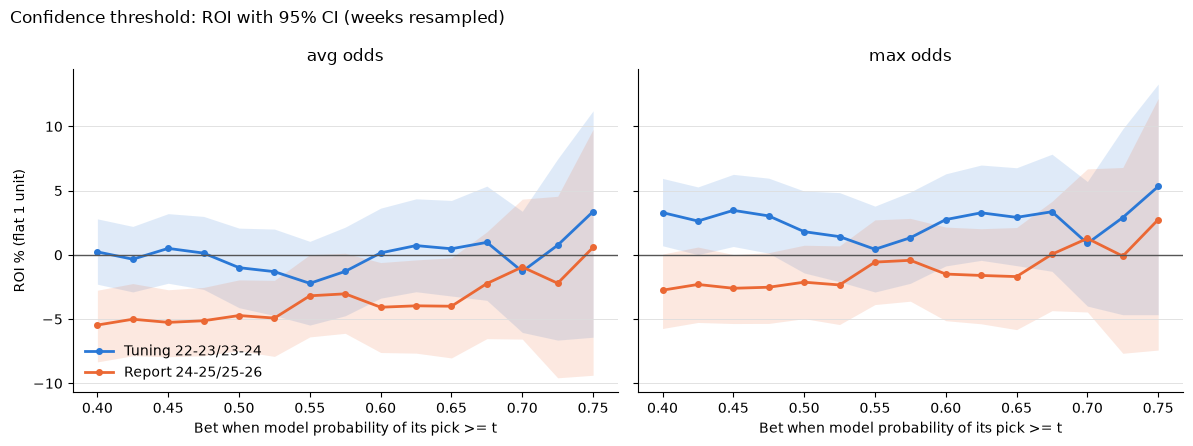

In [10]:
thr = results[results["family"] == "threshold"].copy()
thr["t"] = thr["variant"].str.slice(3).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, source in zip(axes, ["avg", "max"]):
    for period, colour, label in [("tune", TUNE_COLOUR, "Tuning 22-23/23-24"), ("report", REPORT_COLOUR, "Report 24-25/25-26")]:
        d = thr[(thr["source"] == source) & (thr["period"] == period) & (thr["bets"] >= 30)].sort_values("t")
        ax.fill_between(d["t"], d["roi_ci_low"], d["roi_ci_high"], color=colour, alpha=0.15, linewidth=0)
        ax.plot(d["t"], d["roi"], color=colour, linewidth=2, marker="o", markersize=4, label=label)
    ax.axhline(0, color="#555555", linewidth=1)
    ax.set_title(f"{source} odds")
    ax.set_xlabel("Bet when model probability of its pick >= t")
    ax.grid(axis="y", color="#dddddd", linewidth=0.6)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("ROI % (flat 1 unit)")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Confidence threshold: ROI with 95% CI (weeks resampled)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Threshold table

In [11]:
def compact(family):
    rows = results[results["family"] == family].copy()
    rows["roi [CI]"] = rows.apply(fmt, axis=1)
    wide = rows.pivot_table(index="variant", columns=["source", "period"], values="roi [CI]", aggfunc="first")
    bets = rows[rows["source"] == "avg"].pivot_table(index="variant", columns="period", values="bets_per_week")
    wide[("bets/wk", "tune")], wide[("bets/wk", "report")] = bets["tune"].round(1), bets["report"].round(1)
    clv = rows[rows["period"] == "report"].pivot_table(index="variant", columns="source", values="clv")
    wide[("CLV report", "avg")], wide[("CLV report", "max")] = clv["avg"].round(2), clv["max"].round(2)
    order = [("avg", "tune"), ("avg", "report"), ("max", "tune"), ("max", "report"),
             ("bets/wk", "tune"), ("bets/wk", "report"), ("CLV report", "avg"), ("CLV report", "max")]
    return wide[order]

compact("threshold")

source                    avg                                        max                       bets/wk        CLV report      
period                   tune               report                  tune                report    tune report        avg   max
variant                                                                                                                       
p>=0.400    +0.2 [-2.3, +2.8]    -5.5 [-8.3, -2.8]     +3.3 [+0.7, +6.0]     -2.7 [-5.7, +0.1]    56.0   55.1      -0.49 -1.02
p>=0.425    -0.3 [-2.9, +2.2]    -5.0 [-7.9, -2.2]     +2.6 [+0.0, +5.3]     -2.3 [-5.3, +0.6]    50.2   50.3      -0.46 -0.98
p>=0.450    +0.5 [-2.2, +3.2]    -5.3 [-7.9, -2.7]     +3.5 [+0.7, +6.3]     -2.6 [-5.3, +0.0]    44.8   45.6      -0.49 -1.00
p>=0.475    +0.1 [-2.7, +3.0]    -5.1 [-7.9, -2.5]     +3.0 [+0.1, +6.0]     -2.5 [-5.3, +0.2]    39.6   40.6      -0.44 -0.94
p>=0.500    -1.0 [-4.1, +2.1]    -4.7 [-7.5, -1.9]     +1.8 [-1.4, +5.0]     -2.1 [-5.0, +0.7]    34.5   36.1      -0.38 -0.85
p>=0.525    -1.3 [-4.7, +2.0]    -4.9 [-7.9, -2.0]     +1.4 [-2.1, +4.8]     -2.3 [-5.4, +0.7]    30.0   31.9      -0.34 -0.80
p>=0.550    -2.2 [-5.5, +1.0]    -3.2 [-6.4, +0.0]     +0.4 [-2.9, +3.8]     -0.6 [-3.9, +2.7]    25.4   27.4      -0.35 -0.78
p>=0.575    -1.3 [-4.7, +2.2]    -3.0 [-6.1, +0.1]     +1.3 [-2.2, +4.9]     -0.4 [-3.6, +2.8]    21.2   22.6      -0.30 -0.72
p>=0.600    +0.2 [-3.4, +3.6]    -4.1 [-7.6, -0.6]     +2.7 [-0.9, +6.3]     -1.5 [-5.1, +2.2]    17.0   18.9      -0.31 -0.70
p>=0.625    +0.7 [-2.9, +4.4]    -4.0 [-7.7, -0.4]     +3.3 [-0.4, +7.0]     -1.6 [-5.4, +2.0]    13.2   15.3      -0.30 -0.78
p>=0.650    +0.5 [-3.2, +4.2]    -4.0 [-8.0, -0.2]     +2.9 [-0.8, +6.8]     -1.7 [-5.8, +2.1]     9.6   11.9      -0.26 -0.65
p>=0.675    +1.0 [-3.5, +5.4]    -2.2 [-6.5, +1.8]     +3.4 [-1.3, +7.8]     +0.1 [-4.3, +4.2]     6.8    8.4      -0.30 -0.72
p>=0.700    -1.3 [-6.0, +3.4]    -0.9 [-6.6, +4.3]     +0.9 [-4.0, +5.7]     +1.3 [-4.4, +6.7]     4.1    5.6      -0.32 -0.81
p>=0.725    +0.8 [-6.6, +7.5]    -2.2 [-9.6, +4.6]     +2.9 [-4.7, +9.8]     -0.1 [-7.7, +6.8]     1.9    3.2      -0.26 -0.75
p>=0.750   +3.4 [-6.4, +11.2]    +0.6 [-9.4, +9.8]    +5.3 [-4.7, +13.3]    +2.7 [-7.4, +12.2]     0.6    1.0      -0.81 -1.19
p>=0.775  +13.8 [+9.5, +20.0]  +5.7 [-17.0, +16.3]  +16.3 [+11.5, +23.3]   +7.6 [-15.4, +18.3]     0.1    0.2      -0.45 -0.81
p>=0.800    +nan [+nan, +nan]  +11.3 [+8.0, +18.0]     +nan [+nan, +nan]  +13.2 [+10.0, +20.0]     0.0    0.1       0.42  0.18

### Top-N per week

In [12]:
compact("top-N")

source                  avg                                    max                     bets/wk        CLV report      
period                 tune             report                tune              report    tune report        avg   max
variant                                                                                                               
top 1    +3.2 [-6.8, +11.9]  +0.3 [-9.3, +9.2]  +5.3 [-4.9, +14.3]  +2.6 [-7.3, +11.7]     1.0    1.0      -1.00 -1.42
top 10    +1.5 [-1.9, +5.1]  -2.8 [-7.0, +1.5]   +4.0 [+0.5, +7.6]   -0.5 [-4.8, +3.8]     9.7    9.9      -0.21 -0.79
top 20    -0.2 [-3.8, +3.5]  -3.4 [-6.8, -0.1]   +2.4 [-1.3, +6.2]   -0.8 [-4.3, +2.7]    19.4   19.7      -0.34 -0.77
top 3     +2.3 [-3.6, +7.8]  -1.1 [-8.8, +6.0]  +4.5 [-1.5, +10.1]   +1.2 [-6.7, +8.4]     2.9    3.0      -0.43 -0.84
top 5     -2.6 [-8.0, +2.7]  -3.0 [-8.5, +2.4]   -0.4 [-5.9, +5.0]   -0.8 [-6.3, +4.8]     4.9    4.9      -0.38 -0.78

### Home picks only / away picks only

In [13]:
pd.concat({"home": compact("home only"), "away": compact("away only")})

source                            avg                                          max                       bets/wk        CLV report      
period                           tune                report                   tune                report    tune report        avg   max
     variant                                                                                                                            
home H p>=0.400     +0.3 [-3.2, +3.8]     -6.0 [-9.9, -2.1]      +3.3 [-0.3, +6.9]     -3.4 [-7.4, +0.6]    35.9   35.5      -0.54 -1.01
     H p>=0.425     -0.4 [-3.8, +3.2]     -5.6 [-9.6, -1.7]      +2.6 [-1.0, +6.2]     -3.0 [-7.1, +1.0]    32.9   32.8      -0.52 -0.97
     H p>=0.450     -0.3 [-4.0, +3.3]     -6.0 [-9.8, -2.3]      +2.6 [-1.2, +6.3]     -3.5 [-7.4, +0.4]    29.8   30.0      -0.54 -1.00
     H p>=0.475     -0.7 [-4.3, +2.8]     -6.0 [-9.8, -2.3]      +2.1 [-1.5, +5.7]     -3.5 [-7.4, +0.3]    26.5   27.1      -0.45 -0.90
     H p>=0.500     -1.5 [-5.2, +2.1]     -5.8 [-9.4, -2.1]      +1.3 [-2.6, +5.0]     -3.3 [-7.0, +0.4]    23.3   24.5      -0.41 -0.81
     H p>=0.525     -1.3 [-5.2, +2.4]     -5.8 [-9.6, -2.1]      +1.4 [-2.6, +5.2]     -3.4 [-7.3, +0.4]    20.3   21.9      -0.37 -0.77
     H p>=0.550     -2.1 [-5.8, +1.5]     -3.6 [-7.8, +0.5]      +0.6 [-3.3, +4.2]     -1.2 [-5.5, +3.1]    17.3   18.9      -0.31 -0.68
     H p>=0.575     -0.5 [-4.6, +3.5]     -4.2 [-8.0, -0.4]      +2.1 [-2.1, +6.2]     -1.8 [-5.7, +2.1]    14.7   15.9      -0.33 -0.70
     H p>=0.600     +0.6 [-3.9, +4.8]     -5.8 [-9.9, -1.6]      +3.1 [-1.4, +7.5]     -3.4 [-7.6, +0.8]    12.1   13.4      -0.32 -0.68
     H p>=0.625     +1.5 [-3.0, +5.8]     -5.3 [-9.7, -1.0]      +4.1 [-0.6, +8.4]     -3.0 [-7.5, +1.4]     9.6   11.2      -0.24 -0.62
     H p>=0.650     +0.2 [-4.1, +4.5]     -4.2 [-8.9, +0.4]      +2.6 [-1.9, +7.0]     -1.9 [-6.7, +2.7]     7.3    9.1      -0.24 -0.65
     H p>=0.675     -0.7 [-6.2, +4.6]     -1.6 [-6.7, +3.4]      +1.6 [-4.1, +7.0]     +0.7 [-4.6, +5.8]     5.4    6.5      -0.24 -0.67
     H p>=0.700     -0.4 [-5.7, +4.6]     -0.9 [-7.1, +5.1]      +1.7 [-3.7, +6.9]     +1.3 [-5.1, +7.4]     3.5    4.5      -0.21 -0.69
     H p>=0.725     +2.4 [-4.3, +8.7]     -1.0 [-9.0, +6.3]     +4.6 [-2.4, +11.0]     +1.1 [-7.2, +8.5]     1.8    2.6      -0.09 -0.61
     H p>=0.750    +5.6 [-4.8, +13.1]    -2.1 [-12.9, +7.9]     +7.6 [-3.0, +15.3]   -0.1 [-11.1, +10.3]     0.6    0.9      -0.70 -1.12
     H p>=0.775   +13.8 [+9.5, +20.0]   +5.1 [-17.3, +16.5]   +16.3 [+11.5, +23.3]   +6.9 [-15.9, +18.6]     0.1    0.2      -0.54 -0.93
     H p>=0.800     +nan [+nan, +nan]   +11.3 [+8.0, +18.0]      +nan [+nan, +nan]  +13.2 [+10.0, +20.0]     0.0    0.1       0.42  0.18
away A p>=0.400     +0.1 [-4.7, +4.9]     -4.5 [-8.7, -0.3]      +3.3 [-1.7, +8.2]     -1.6 [-5.9, +2.8]    20.1   19.5      -0.42 -1.05
     A p>=0.425     -0.3 [-5.0, +4.3]     -3.9 [-8.4, +0.8]      +2.8 [-2.1, +7.5]     -0.9 [-5.7, +3.9]    17.3   17.5      -0.35 -0.99
     A p>=0.450     +2.2 [-2.6, +6.9]     -3.8 [-8.4, +0.8]     +5.3 [+0.4, +10.1]     -0.9 [-5.6, +3.8]    15.0   15.5      -0.38 -0.99
     A p>=0.475     +1.9 [-3.2, +6.9]     -3.4 [-7.9, +1.2]     +4.9 [-0.4, +10.1]     -0.5 [-5.2, +4.2]    13.2   13.5      -0.42 -1.02
     A p>=0.500     +0.0 [-5.8, +5.8]     -2.5 [-7.7, +2.7]      +2.9 [-3.0, +8.8]     +0.4 [-4.9, +5.9]    11.2   11.6      -0.33 -0.94
     A p>=0.525     -1.3 [-7.6, +4.9]     -2.9 [-8.5, +2.7]      +1.5 [-4.9, +7.8]     -0.0 [-5.8, +5.9]     9.7   10.0      -0.29 -0.87
     A p>=0.550     -2.6 [-9.2, +4.2]     -2.2 [-8.0, +3.7]      +0.1 [-6.7, +7.1]     +0.8 [-5.3, +7.1]     8.1    8.5      -0.43 -1.01
     A p>=0.575    -3.1 [-10.2, +3.8]     -0.2 [-6.5, +6.0]      -0.5 [-7.8, +6.7]     +2.9 [-3.7, +9.6]     6.5    6.8      -0.24 -0.76
     A p>=0.600     -0.9 [-7.9, +6.5]     +0.0 [-6.8, +6.6]      +1.8 [-5.4, +9.3]    +3.2 [-4.0, +10.4]     4.9    5.5      -0.28 -0.77
     A p>=0.625     -1.4 [-

### By league

Every pick per league, then the "profitable leagues" rule (leagues chosen from the
tuning seasons). Per-league thresholds: tuning vs report ROI at avg.

In [14]:
pd.concat({"league": compact("league"), "profitable leagues": compact("profitable leagues")})

source                                                                avg                                      max                      bets/wk        CLV report      
period                                                               tune               report                tune               report    tune report        avg   max
                   variant                                                                                                                                             
league             D1 all                              -5.4 [-13.8, +2.7]   -8.3 [-16.7, +0.2]  -2.6 [-11.2, +5.8]   -5.5 [-14.1, +3.3]     7.9    7.9      -0.57 -1.12
                   E0 all                              +4.2 [-2.8, +11.4]   -5.3 [-12.1, +1.5]  +7.5 [+0.2, +14.9]    -2.9 [-9.9, +4.2]     9.9    9.9      -0.72 -1.33
                   F1 all                               -1.7 [-9.0, +5.2]   -4.0 [-11.6, +4.1]   +1.7 [-5.9, +8.9]    -1.0 [-8.8, +7.3]     8.9    7.9       0.05 -0.34
                   I1 all                               -0.5 [-7.9, +7.4]   -5.6 [-12.3, +0.7]  +2.6 [-5.0, +10.8]    -2.5 [-9.4, +4.1]     9.9    9.9      -0.93 -1.10
                   N1 all                               -0.4 [-6.8, +6.0]  -13.5 [-20.0, -7.0]   +2.7 [-4.0, +9.4]  -11.2 [-17.9, -4.5]     7.9    7.9      -0.71 -1.48
                   P1 all                               +1.3 [-5.7, +8.6]   -7.1 [-15.3, +0.4]  +4.4 [-2.9, +12.0]   -4.4 [-12.7, +3.5]     7.9    7.9      -0.02 -0.89
                   SP1 all                              +3.3 [-2.7, +9.5]    +0.2 [-5.9, +6.1]  +6.5 [+0.3, +12.9]    +3.2 [-3.1, +9.4]     9.9    9.9      -0.47 -0.94
profitable leagues tune-profitable leagues: E0,P1,SP1   +3.1 [-0.3, +6.5]    -3.9 [-8.1, +0.0]   +6.2 [+2.7, +9.8]    -1.1 [-5.5, +2.9]    27.7   27.7      -0.43 -1.06

In [15]:
lt = results[(results["family"] == "league threshold") & (results["source"] == "avg")].copy()
lt["Div"], lt["t"] = lt["variant"].str.split().str[0], lt["variant"].str.split(">=").str[1]
grid = lt.pivot_table(index=["Div", "period"], columns="t", values="roi").reindex(["tune", "report", "26-27"], level=1)
print("ROI % at avg, per league and threshold (blank = no bets)")
grid.round(1)

ROI % at avg, per league and threshold (blank = no bets)


t           0.400  0.425  0.450  0.475  0.500  0.525  0.550  0.575  0.600  0.625  0.650  0.675  0.700  0.725  0.750  0.775  0.800
Div period                                                                                                                       
D1  tune     -3.0   -2.2   -0.1   -2.8   -3.4   -5.3   -9.0   -4.7   -2.1    1.4    3.9    1.0   -5.7    7.5   -7.6    NaN    NaN
    report   -6.2   -7.1   -4.3   -6.1   -3.3   -3.9   -5.6   -4.2   -3.7   -1.6   -1.2    0.2   -4.6   -7.6  -35.5  -45.5    NaN
    26-27     1.5   -7.3  -10.2   -3.5  -16.9  -15.4  -16.1  -20.9  -15.0  -26.4  -22.3  -41.5  -65.3  -48.0  -48.0    NaN    NaN
E0  tune      0.8   -0.3    2.3    1.2   -0.2   -0.9   -2.8   -3.7   -3.1   -6.2   -5.8   -6.2   -4.4    1.6    3.5   13.8    NaN
    report   -5.1   -6.2   -6.4   -7.3   -9.1   -9.8   -8.7  -11.1  -13.2  -10.5  -11.0  -11.4   -2.0   -4.5   12.8   15.0   11.3
    26-27    -6.1   -6.1  -20.9  -18.2  -22.5  -19.6   -4.5    6.9   20.7   11.4    5.6   35.7   27.7   24.0    NaN    NaN    NaN
F1  tune     -4.6   -5.6   -8.5   -8.5   -8.0   -4.8   -1.9   -1.9   -3.2   -0.6   -5.7    4.5   -6.6  -14.5    NaN    NaN    NaN
    report   -4.6   -4.8   -5.4   -4.9   -3.5    0.3    4.0    0.6   -3.7   -5.1   -4.7   -1.9  -12.2   -2.6    3.2   13.0    NaN
    26-27     2.3   -6.2   -0.2  -11.3    5.7   -4.8   -1.8   -7.9   -4.1    3.1  -10.8  -20.3   19.5    NaN    NaN    NaN    NaN
I1  tune      1.2    2.2    3.7    1.9   -1.9   -1.9   -3.7   -6.6   -1.8   -3.2   -3.7   -3.6   -5.5   -8.7  -43.0    NaN    NaN
    report   -5.4   -2.1   -1.7   -1.9   -1.9   -5.5   -6.3   -0.3   -0.5   -3.0   -0.1    0.7    2.8   20.4    NaN    NaN    NaN
    26-27    11.9   13.4   18.0   24.9   25.8   38.7   30.1   34.1   35.4   36.5   31.9   24.6   21.7   19.0    NaN    NaN    NaN
N1  tune      3.1   -0.6    1.9    2.9   -0.7   -2.5   -3.5    0.3    0.8    2.6   -0.1    2.4   -3.6   -4.7    9.1    NaN    NaN
    report  -13.8  -12.3  -12.4  -10.8   -8.6   -7.6   -4.6   -2.4   -2.3   -3.8   -4.2   -1.8   -1.7   -9.4   -7.9   15.0    NaN
    26-27   -13.6  -12.8  -13.8  -11.8  -12.0  -12.6  -16.3  -28.9  -26.1  -29.6  -29.3  -35.8  -43.0  -44.3  -46.5    NaN    NaN
P1  tune     -0.3    0.1    3.8    6.1    5.9    5.3    5.0    4.5    4.7    3.4    7.1    7.8    8.8    4.6   10.0    NaN    NaN
    report   -4.1   -2.4   -7.0   -5.5   -5.4   -6.2    0.4   -0.7   -1.5   -2.1   -3.3    1.2    1.2   -0.6    6.6    9.7    NaN
    26-27     3.4    0.1   -0.8   -0.9    4.7    4.9    0.3    4.1   10.4   -0.9    3.8    1.9    6.0   19.5   18.0    NaN    NaN
SP1 tune      3.8    3.2    0.0    0.4    1.4    0.8    0.8    3.9    5.9    9.0    5.9    1.1    1.5   13.2   19.7    NaN    NaN
    report   -0.0   -1.1   -0.8   -0.0   -0.8   -0.7   -0.4   -1.4   -1.6   -0.7   -1.4   -0.7    8.0    9.4   16.2    NaN    NaN
    26-27    -7.2   -9.9   -7.4   -3.8    2.9   -2.0    8.6    8.8    6.9   18.1   14.5   11.1   16.3    8.0    9.0    NaN    NaN

In [16]:
# How often does a league-threshold cell that was positive in tuning stay positive in the report seasons?
pair = lt[lt["bets"] > 0].pivot_table(index="variant", columns="period", values=["roi", "bets"])
pair = pair[(pair[("bets", "tune")] >= 30) & (pair[("bets", "report")] >= 30)]
pos = pair[("roi", "tune")] > 0
print(f"{len(pair)} league-threshold cells with >= 30 bets in both periods; {pos.sum()} positive in tuning,"
      f" of which {(pair.loc[pos, ('roi', 'report')] > 0).sum()} positive in report;"
      f" {(pair.loc[~pos, ('roi', 'report')] > 0).sum()} of {(~pos).sum()} negative-in-tuning cells positive in report.")
print(f"Correlation of tuning and report ROI across cells: {pair[('roi', 'tune')].corr(pair[('roi', 'report')]):+.2f}")

91 league-threshold cells with >= 30 bets in both periods; 44 positive in tuning, of which 5 positive in report; 4 of 47 negative-in-tuning cells positive in report.
Correlation of tuning and report ROI across cells: +0.27


### Minimum odds on top of the threshold

Confident picks come at short prices, where the margin takes a larger share.
ROI % at avg, tuning vs report.

In [17]:
mo = results[(results["family"] == "min odds") & (results["source"] == "avg")].copy()
mo["t"] = mo["variant"].str.extract(r"p>=([\d.]+)")[0]
mo["min odds"] = mo["variant"].str.extract(r"odds>=([\d.]+)")[0]
print("ROI % at avg")
display(mo.pivot_table(index=["min odds", "period"], columns="t", values="roi").reindex(["tune", "report", "26-27"], level=1).round(1))
print("Bets per week, tuning seasons")
mo[mo["period"] == "tune"].pivot_table(index="min odds", columns="t", values="bets_per_week").round(1)

ROI % at avg


t                0.400  0.425  0.450  0.475  0.500  0.525  0.550  0.575  0.600  0.625  0.650  0.675  0.700  0.725  0.750  0.775
min odds period                                                                                                                
1.20     tune      0.3   -0.3    0.6    0.2   -1.0   -1.4   -2.4   -1.4    0.3    0.9    0.6    0.9   -2.5   -0.2   -4.6   23.0
         report   -5.8   -5.4   -5.6   -5.6   -5.2   -5.5   -3.7   -3.6   -4.9   -5.0   -5.4   -3.5   -1.9   -3.3   -7.1   35.0
         26-27    -1.0   -3.6   -4.3   -2.1    0.3    1.1    2.1    1.0    6.1    4.0    3.7    5.7   12.6   23.8   20.0    NaN
1.30     tune      0.3   -0.3    0.7    0.3   -1.1   -1.5   -2.7   -1.5    0.8    2.0    1.3    1.6   -4.6   11.9  -11.7    NaN
         report   -6.1   -5.6   -6.0   -5.9   -5.6   -6.0   -4.1   -4.1   -5.9   -6.4   -7.5   -4.6    2.9   13.8   35.0   35.0
         26-27    -1.3   -4.3   -5.1   -2.9   -0.3    0.8    1.8   -0.4    6.2    3.1    2.8    7.2   16.0   31.0    NaN    NaN
1.50     tune      0.3   -0.5    0.8    0.2   -1.6   -2.6   -4.4   -3.6   -1.3   -0.9   -0.8  -15.0   -9.6 -100.0 -100.0    NaN
         report   -6.9   -6.5   -7.0   -7.1   -6.9   -7.6   -4.9   -5.4   -9.4  -12.4  -15.8   -9.1    4.9   57.5    NaN    NaN
         26-27    -2.1   -5.8   -7.2   -4.2   -0.7    1.0    2.1   -1.9    4.0   -8.9   -3.7  -15.5    NaN    NaN    NaN    NaN
1.80     tune      0.8   -0.7    1.8    1.3   -1.4   -4.7   -8.4  -15.7  -14.7   -8.7  -20.4   -7.5    NaN    NaN    NaN    NaN
         report   -7.5   -6.9   -7.9   -8.3   -8.0   -9.4   -4.2   -8.6   -1.4  -16.7  -45.2 -100.0    NaN    NaN    NaN    NaN
         26-27     3.3   -2.5   -3.0   -1.5    4.9    4.8    8.7  -10.0   10.9   26.3 -100.0    NaN    NaN    NaN    NaN    NaN

Bets per week, tuning seasons


t,0.400,0.425,0.450,0.475,0.500,0.525,0.550,0.575,0.600,0.625,0.650,0.675,0.700,0.725,0.750,0.775,0.800
min odds,,,,,,,,,,,,,,,,,
1.20,53.5,47.7,42.3,37.1,32.0,27.5,22.9,18.6,14.5,10.7,7.2,4.6,2.3,0.7,0.1,0.0,0.0
1.30,50.1,44.3,38.9,33.7,28.6,24.1,19.5,15.3,11.2,7.7,4.5,2.4,1.0,0.2,0.0,0.0,0.0
1.50,42.0,36.3,30.9,25.8,20.8,16.4,12.1,8.3,5.0,2.8,1.2,0.4,0.1,0.0,0.0,0.0,0.0
1.80,29.6,24.1,19.1,14.7,10.5,7.4,4.5,2.5,1.1,0.4,0.1,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
# Where the money goes: argmax picks by odds band, every pick, avg
band = pd.cut(ODDS["avg"], [1, 1.3, 1.5, 1.8, 2.5, 4, 100], labels=["<1.30", "1.30-1.50", "1.50-1.80", "1.80-2.50", "2.50-4", ">4"])
rows = {}
for b in band.categories:
    for period in PERIODS:
        rows[(b, period)] = evaluate(where(np.asarray(band == b)), "avg", period)
bands = pd.DataFrame(rows).T[["bets", "hit_rate", "avg_odds", "roi", "roi_ci_low", "roi_ci_high", "clv"]].astype(float).round(2)
bands = bands.unstack(1).swaplevel(axis=1)
bands.reindex(index=list(band.categories), columns=[(p, m) for p in PERIODS for m in ["bets", "hit_rate", "avg_odds", "roi", "roi_ci_low", "roi_ci_high", "clv"]])

tune                                                        report                                                        26-27                                                        
             bets hit_rate avg_odds    roi roi_ci_low roi_ci_high   clv    bets hit_rate avg_odds    roi roi_ci_low roi_ci_high   clv   bets hit_rate avg_odds     roi roi_ci_low roi_ci_high    clv
<1.30       482.0    82.57     1.21  -0.74      -4.71        3.18 -0.08   453.0    83.22     1.21   0.08      -4.67        4.38 -0.58   72.0    80.56     1.19   -3.83     -16.61        4.57  -0.04
1.30-1.50   631.0    71.47     1.40   0.21      -4.48        4.93 -0.06   630.0    69.84     1.40  -2.37      -7.28        2.62 -0.40   88.0    72.73     1.40    1.77     -11.97       14.08   0.18
1.50-1.80   965.0    60.00     1.66  -0.39      -6.07        5.41 -0.18  1044.0    57.38     1.66  -5.00     -10.47        0.42 -0.49  138.0    54.35     1.65  -10.68     -29.29        9.18   0.37
1.80-2.50  1868.0    47.43     2.13   0.07      -4.30        4.26 -0.04  1887.0    44.94     2.13  -5.00      -9.69       -0.46 -0.40  242.0    50.41     2.14    7.70      -5.69       22.75  -0.10
2.50-4      833.0    35.65     2.89   1.34      -7.77       10.74 -0.82   703.0    29.16     2.86 -16.86     -26.11       -7.47 -0.89   99.0    27.27     2.91  -19.74     -45.56        6.65  -0.92
>4           23.0    30.43     4.36  31.83     -51.94      118.27  3.91    11.0    18.18     4.39 -24.55    -100.00       85.64  2.61    2.0    50.00     4.17  109.50    -100.00      319.00 -14.36

### Confidence relative to the market (`conf / q`)

Ranks the argmax pick by how much more confident the model is than the
de-margined market.

In [19]:
pd.concat({"ratio threshold": compact("ratio threshold"), "ratio top-N": compact("ratio top-N")})

source                                          avg                                        max                      bets/wk        CLV report      
period                                         tune               report                  tune               report    tune report        avg   max
                variant                                                                                                                            
ratio threshold p/q>=0.900        -0.1 [-3.1, +2.9]    -6.9 [-9.8, -4.2]     +3.1 [+0.0, +6.3]    -4.1 [-7.1, -1.3]    49.2   52.8      -0.48 -1.04
                p/q>=0.925        +0.3 [-2.8, +3.5]   -7.3 [-10.2, -4.4]     +3.6 [+0.4, +6.9]    -4.4 [-7.6, -1.5]    45.2   49.0      -0.46 -1.03
                p/q>=0.950        +0.2 [-3.1, +3.5]   -7.5 [-10.7, -4.4]     +3.5 [+0.1, +7.0]    -4.6 [-7.9, -1.4]    41.4   44.8      -0.46 -1.04
                p/q>=0.975        -0.7 [-4.1, +2.8]   -7.8 [-11.4, -4.3]     +2.7 [-0.9, +6.3]    -5.0 [-8.7, -1.3]    37.2   40.3      -0.49 -1.05
                p/q>=1.000        -0.9 [-5.0, +3.3]   -8.8 [-12.8, -4.9]     +2.5 [-1.8, +6.9]   -6.0 [-10.1, -2.0]    33.0   36.0      -0.48 -1.06
                p/q>=1.025        -1.4 [-5.5, +2.8]   -8.8 [-13.1, -4.7]     +2.0 [-2.3, +6.4]   -6.0 [-10.4, -1.7]    29.5   32.2      -0.42 -1.02
                p/q>=1.050        +0.3 [-4.2, +5.0]   -9.4 [-14.0, -5.0]     +3.8 [-0.9, +8.7]   -6.5 [-11.3, -1.9]    26.3   28.4      -0.42 -1.06
                p/q>=1.075        -0.3 [-5.5, +5.1]  -10.4 [-15.4, -5.8]     +3.2 [-2.2, +8.9]   -7.5 [-12.7, -2.7]    23.4   24.6      -0.43 -1.07
                p/q>=1.100        -0.6 [-6.5, +5.5]  -10.1 [-15.6, -4.8]     +3.0 [-3.1, +9.4]   -7.2 [-12.9, -1.6]    20.8   21.4      -0.43 -1.07
                p/q>=1.125        -1.4 [-7.9, +5.4]   -9.9 [-15.5, -4.1]     +2.2 [-4.5, +9.3]   -6.9 [-12.8, -0.9]    18.3   18.2      -0.44 -1.08
                p/q>=1.150        -0.7 [-7.7, +6.4]  -12.6 [-19.6, -5.8]    +3.0 [-4.3, +10.4]   -9.6 [-16.9, -2.5]    16.1   15.5      -0.46 -1.12
                p/q>=1.175        -2.0 [-9.9, +6.0]  -13.4 [-21.1, -5.7]    +1.8 [-6.5, +10.2]  -10.3 [-18.4, -2.3]    14.0   13.3      -0.60 -1.28
                p/q>=1.200       -3.2 [-11.4, +5.5]  -11.7 [-19.9, -3.4]     +0.6 [-8.0, +9.7]   -8.5 [-17.2, +0.1]    12.1   11.4      -0.45 -1.13
                p/q>=1.225       -4.6 [-14.4, +5.6]  -12.0 [-20.8, -3.0]    -0.8 [-10.9, +9.9]   -8.8 [-18.0, +0.6]    10.3    9.5      -0.48 -1.14
                p/q>=1.250       -4.3 [-14.5, +6.4]  -12.5 [-22.3, -2.5]   -0.3 [-11.1, +10.8]   -9.1 [-19.5, +1.2]     8.9    7.9      -0.62 -1.30
                p/q>=1.275       -3.4 [-14.0, +7.8]  -10.0 [-20.8, +1.2]   +0.6 [-10.3, +12.3]   -6.5 [-17.8, +5.2]     7.6    6.7      -0.64 -1.41
                p/q>=1.300      -0.9 [-13.1, +11.8]  -10.5 [-23.4, +2.6]    +3.4 [-9.4, +16.7]   -7.0 [-20.4, +6.6]     6.4    5.6      -0.50 -1.35
ratio top-N     top 1 by p/q   +10.4 [-25.4, +48.2]  -3.1 [-35.9, +32.1]  +16.2 [-21.7, +56.1]  +1.8 [-32.7, +38.7]     1.0    1.0      -0.75 -1.52
                top 10 by p/q    -2.3 [-11.8, +7.5]  -13.0 [-22.4, -4.1]    +1.6 [-8.4, +11.9]   -9.8 [-19.6, -0.5]     9.7    9.9      -0.42 -1.12
                top 20 by p/q     -2.5 [-8.6, +3.9]  -10.9 [-16.5, -5.3]     +1.0 [-5.3, +7.8]   -7.9 [-13.9, -2.1]    19.4   19.7      -0.51 -1.17
                top 3 by p/q    -6.8 [-24.6, +11.7]  -15.6 [-32.0, +1.5]   -2.4 [-20.9, +17.0]  -12.0 [-29.2, +5.8]     2.9    3.0      -0.51 -1.16
                top 5 by p/q    -2.1 [-15.7, +12.3]   -4.4 [-17.4, +8.5]   +2.3 [-12.0, +17.5]  -0.7 [-14.3, +12.8]     4.9    4.9      -0.16 -0.90

### Tuning vs report across all variants

If tuning ROI carried information about future ROI, variants that did well in
tuning would tend to do well in the report seasons.

In [20]:
wide = results[results["source"] == "avg"].pivot_table(index=["family", "variant"], columns="period", values=["roi", "bets"])
wide = wide[(wide[("bets", "tune")] >= MIN_TUNE_BETS) & (wide[("bets", "report")] >= MIN_TUNE_BETS)]
print(f"{len(wide)} variants with >= {MIN_TUNE_BETS} bets in both periods")
print(f"Correlation tuning vs report ROI: {wide[('roi', 'tune')].corr(wide[('roi', 'report')]):+.2f}")
print(f"Positive in tuning: {(wide[('roi', 'tune')] > 0).sum()}; positive in report: {(wide[('roi', 'report')] > 0).sum()};"
      f" positive in both: {((wide[('roi', 'tune')] > 0) & (wide[('roi', 'report')] > 0)).sum()}")
top10 = wide.sort_values(("roi", "tune"), ascending=False).head(10)["roi"][["tune", "report", "26-27"]].round(2)
top10

180 variants with >= 150 bets in both periods
Correlation tuning vs report ROI: +0.20
Positive in tuning: 78; positive in report: 6; positive in both: 2


period                         tune  report  26-27
family           variant                          
league threshold P1 p>=0.475   6.07   -5.54  -0.92
                 P1 p>=0.500   5.93   -5.37   4.67
                 SP1 p>=0.600  5.86   -1.56   6.92
                 P1 p>=0.525   5.33   -6.18   4.85
                 P1 p>=0.550   4.97    0.41   0.29
                 P1 p>=0.600   4.68   -1.50  10.39
                 P1 p>=0.575   4.48   -0.71   4.09
league           E0 all        4.22   -5.34  -3.78
league threshold SP1 p>=0.575  3.91   -1.39   8.84
                 SP1 p>=0.400  3.83   -0.04  -7.24

## Variant log

Every variant x source x period above goes to `data/processed/betting_variants.csv`
(P8-03's rows replaced on each run).

In [21]:
log = log_variants(results.drop(columns="profit"), ticket="P8-03")
print(f"Logged {results.groupby(['family', 'variant']).ngroups} P8-03 variants "
      f"({len(results)} rows); log now holds", log.groupby("ticket")["variant"].nunique().to_dict())

Logged 274 P8-03 variants (2466 rows); log now holds {'P8-03': 274, 'P8-04': 331, 'P8-05': 67, 'P8-06': 134}


In [22]:
# For P8-07: weekly P&L of every P8-03 variant (the multiple-testing correction resamples
# the same weeks for all variants) and the chosen rule's individual bets
from betting.variants import log_chosen_bets, log_variant_weeks, weekly_pnl

WEEK_LABEL = oos["Week"].to_numpy()
KEYS = oos["MatchKey"].to_numpy()
SEASON = oos["Season"].to_numpy()

def chosen_frame(rule_name, source, bet, selection, odds, closing, profit):
    with np.errstate(divide="ignore", invalid="ignore"):
        clv = np.log(odds / closing)
    return pd.DataFrame({
        "rule": rule_name, "source": source, "Season": SEASON[bet], "Week": WEEK_LABEL[bet], "Div": DIV[bet],
        "MatchKey": KEYS[bet], "selection": selection, "odds": odds, "stake": 1.0, "profit": profit,
        "clv": np.where(np.isfinite(clv), clv, np.nan),
    })

def check_totals(weekly, summary):
    # Weekly profit summed over every period = the summary rows' profit
    want = summary.groupby(["family", "variant", "source"])["profit"].sum()
    got = weekly.groupby(["family", "variant", "source"])["profit"].sum().reindex(want.index, fill_value=0.0)
    assert np.allclose(got, want), (got - want).abs().sort_values().tail()

weekly, bets = [], []
for (family, variant), rule in VARIANTS.items():
    for source in SOURCES:
        bet = rule(source) & priced(source)
        weekly.append(weekly_pnl(WEEK_LABEL[bet], PROFIT[source][bet]).assign(family=family, variant=variant, source=source))
        if (family, variant) == CHOSEN:
            bets.append(chosen_frame(variant, source, bet, PICK[bet], ODDS[source][bet], CLOSE[source][bet], PROFIT[source][bet]))
weekly = pd.concat(weekly, ignore_index=True)
check_totals(weekly, results)
log_variant_weeks(weekly, ticket="P8-03")
log_chosen_bets(pd.concat(bets, ignore_index=True), ticket="P8-03")
print(f"Weekly P&L logged for {weekly.groupby(['family', 'variant']).ngroups} variants; chosen-rule bets:",
      pd.concat(bets).groupby("source").size().to_dict())

Weekly P&L logged for 257 variants; chosen-rule bets: {'avg': 835, 'b365': 835, 'max': 835}


## P8-03 findings

**Verdict: no confidence rule makes money.** Betting only the model's most
confident picks doesn't beat betting every pick; the rule chosen on the tuning
seasons lost in the report seasons, and almost every variant that looked good in
tuning went negative afterwards.

- **Chosen rule (pre-registered):** Primeira Liga picks with p >= 0.475. Tuning
  +6.1% [-1.1, +13.3] at avg (362 bets, 4.7/week). **Report -5.5% [-14.2, +3.2]**
  (409 bets), 26-27 to date -0.9% [-23.3, +23.4] (64 bets). At max: +8.8 -> -3.0 -> +2.2.
  For comparison, every argmax pick lost -6.0% and the market favourite -3.8% in the
  report seasons.
- **Thresholds (all leagues):** tuning ROI hovers around 0 at every t, with no
  trend. Report ROI is negative at every t with a usable number of bets: -5.5% at
  0.40, creeping up to about -1% at 0.70 (5.6 bets/week). Tuning doesn't show that
  rise, so it looks like shorter prices losing less margin, not skill. Higher
  confidence buys fewer bets, not better ones. CLV is negative throughout.
- **Top-N per week:** top 1 +0.3% [-9.3, +9.2], top 3 -1.1%, top 5..20 about -3% in
  the report seasons. Tiny samples; nothing near significance.
- **Home / away only:** both negative in the report seasons at nearly every
  threshold. The model never picks a draw (0 of 10,171), so there is no draw rule.
- **By league:** the leagues that were profitable in tuning (E0, P1, SP1) lost -3.9%
  [-8.1, 0.0] in the report seasons. Of 44 league x threshold cells positive in
  tuning, 5 were positive in the report seasons.
- **Minimum odds:** makes things worse. The longer the minimum price, the bigger the
  report-season loss; the model's picks at 2.50-4 lost -16.9% [-26.1, -7.5].
  Short-priced picks (<1.30) roughly broke even, i.e. lost no more than the margin.
- **Confidence relative to the market (`p / q`):** the more the model exceeds the
  market, the more the pick loses (-6.9% at p/q >= 0.90, about -12% above 1.15).
  Same pattern as P8-02's disagreement analysis, and a warning for P8-04: value
  bets selected by this model are adverse selection.
- **Overfitting check:** of 180 variants with >= 150 bets in both periods, 78 were
  positive in tuning, 6 in the report seasons, 2 in both. The report seasons are a
  worse period for the model overall, and no rule escapes it.

274 variants logged to `data/processed/betting_variants.csv` for P8-07.

# P8-04: Value betting and staking (Kelly)

Instead of the model's pick, back whichever outcome (H, D or A) the
probabilities say is overpriced: **edge = p x odds - 1**, at most one bet per
match (the largest edge). Then size stakes by the edge.

P8-02 and P8-03 make the prior clear: where the model is more confident than the
market, the outcome happens *less* often than the market says. Value bets picked
with the raw model probability are likely to be adverse selection. The
**blended** probability (P8-02's log pool, `p ∝ p_model^a · q^b`, refitted here
on the tuning seasons) is almost the market, so its "edges" are mostly places
where the price taken is longer than the de-margined sharp line.

**Grid (flat 1 unit, every combination):**

| Dimension | Values |
|---|---|
| probability | raw `p_model`, blended (log pool) |
| edge threshold `e` | 0.00 .. 0.30 step 0.02 (16) |
| odds band | any, 1.5-5.0, 1.5-3.0, 2.0-4.0, <= 2.5 |
| sharp line | off / on: also require `p_model > q` (de-margined Pinnacle opening; Avg where Pinnacle is missing, i.e. late 25-26 and all of 26-27) |

The edge is computed at the price taken, so `avg` and `max` select different
bets. Plus one pre-registered hypothesis from P8-02 (logged, *not* eligible for
selection, because P8-02 found it by looking at every season): back away
favourites when the model is more than 10pp below the market.

**Selection rule, fixed before any results were computed** (same as P8-03): among
the grid variants, at `avg` odds in the tuning seasons, with at least 150 tuning
bets, the highest ROI; ties to more bets. Its report-season result is recorded
whatever it is. The staking plans are then run on that rule.

In [23]:
from scipy.optimize import minimize

from betting.staking import (bankroll_path, bankroll_stats, edge_plan, flat_plan, kelly_plan,
                             percent_plan, value_selection, value_strategy)

Y = pd.Categorical(oos["FTR"], categories=OUTCOMES).codes
P_MODEL = oos[["pH", "pD", "pA"]].to_numpy(dtype=float)
Q = oos[["qH", "qD", "qA"]].to_numpy(dtype=float)
assert np.isfinite(P_MODEL).all() and np.isfinite(Q).all() and (Y >= 0).all()

def log_loss(proba, mask):
    return -np.log(np.clip(proba[mask, Y[mask]], 1e-15, 1)).mean()

def log_pool(a, b):
    z = a * np.log(np.clip(P_MODEL, 1e-15, 1)) + b * np.log(np.clip(Q, 1e-15, 1))
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

fit = minimize(lambda t: log_loss(log_pool(*t), PERIOD_MASK["tune"]), x0=[0.2, 0.9], method="Nelder-Mead")
A_POOL, B_POOL = fit.x
P_BLEND = log_pool(A_POOL, B_POOL)
oos[["bH", "bD", "bA"]] = P_BLEND
print(f"Log pool fitted on 22-23/23-24: a = {A_POOL:.3f} (model), b = {B_POOL:.3f} (market)  [P8-02: 0.088, 1.033]")

pd.DataFrame({
    period: {name: log_loss(proba, PERIOD_MASK[period]) for name, proba in
             [("model", P_MODEL), ("market q", Q), ("blend", P_BLEND)]}
    for period in PERIODS
}).round(4)

Log pool fitted on 22-23/23-24: a = 0.088 (model), b = 1.033 (market)  [P8-02: 0.088, 1.033]


,tune,report,26-27
model,0.9697,0.9864,0.9770
market q,0.9503,0.9634,0.9623
blend,0.9489,0.9637,0.9615


### Value-bet evaluator

A rule gives one selection per match (or none), so its flat-stake result is a
vector of per-match profits. `value_eval()` scores that with the same metrics and
week bootstrap as P8-03's `evaluate()`; the next cell checks it against
`simulate()` running `betting.staking.value_strategy`.

In [24]:
PROBS = {"raw": P_MODEL, "blend": P_BLEND}
SHARP = P_MODEL > Q
ODDS3, CLOSE3 = {}, {}
for source in SOURCES:
    pairs = [prices(oos, source, "1X2", sel) for sel in OUTCOMES]
    ODDS3[source] = np.column_stack([o.to_numpy(dtype=float) for o, _ in pairs])
    CLOSE3[source] = np.column_stack([c.to_numpy(dtype=float) for _, c in pairs])

ROWS = np.arange(len(oos))

def value_eval(sel, source, period, edge=None):
    bet = (sel >= 0) & PERIOD_MASK[period]
    weeks = PERIOD_WEEKS[period]
    n = int(bet.sum())
    if n == 0:
        return {"bets": 0, "bets_per_week": 0.0, "hit_rate": np.nan, "avg_odds": np.nan, "roi": np.nan,
                "roi_ci_low": np.nan, "roi_ci_high": np.nan, "clv": np.nan, "profit": 0.0, "mean_edge": np.nan}
    s = sel[bet]
    odds = ODDS3[source][ROWS[bet], s]
    closing = CLOSE3[source][ROWS[bet], s]
    won = Y[bet] == s
    profit = np.where(won, odds - 1, -1.0)
    by_week = (
        pd.DataFrame({"Week": oos.loc[bet, "Week"].to_numpy(), "profit": profit, "staked": 1.0})
        .groupby("Week").sum().reindex(weeks, fill_value=0.0)
    )
    boot = bootstrap_roi(by_week)
    clv = np.log(odds / closing)
    clv = clv[np.isfinite(closing) & (closing > 0)]
    return {
        "bets": n, "bets_per_week": n / len(weeks), "hit_rate": won.mean() * 100,
        "avg_odds": odds.mean(), "roi": profit.sum() / n * 100,
        "roi_ci_low": boot["ci"][0] * 100, "roi_ci_high": boot["ci"][1] * 100,
        "clv": clv.mean() * 100 if len(clv) else np.nan, "profit": profit.sum(),
        "mean_edge": np.nanmean(edge[bet]) * 100 if edge is not None else np.nan,
    }

BANDS = {"any": (1.0, np.inf), "1.5-5.0": (1.5, 5.0), "1.5-3.0": (1.5, 3.0), "2.0-4.0": (2.0, 4.0), "<=2.5": (1.0, 2.5)}

def select(prob, e, band, sharp, source):
    # Selection (index or -1) and edge per match for one grid variant at one source
    return value_selection(PROBS[prob], ODDS3[source], e, BANDS[band], SHARP if sharp else None)

def week_rule(prob, e, band, sharp):
    # The same rule as a simulator strategy (reads only the week's own columns)
    cols = ["pH", "pD", "pA"] if prob == "raw" else ["bH", "bD", "bA"]
    def rule(week):
        p = week[cols].to_numpy(dtype=float)
        sharp_mask = week[["pH", "pD", "pA"]].to_numpy() > week[["qH", "qD", "qA"]].to_numpy()
        return value_selection(p, week[["oH", "oD", "oA"]].to_numpy(dtype=float), e, BANDS[band],
                               sharp_mask if sharp else None)
    rule.p_columns = tuple(cols)
    return rule

In [25]:
# Check: evaluator = simulator, flat 1u, test seasons
test = oos[oos["Season"].isin(TEST)]
rows = []
for args in [("raw", 0.0, "any", False), ("raw", 0.10, "1.5-5.0", True), ("blend", 0.02, "any", False)]:
    for source in SOURCES:
        sim = summarise(simulate(test, value_strategy(week_rule(*args)), source=source)).loc["overall"]
        ev = value_eval(select(*args, source)[0], source, "test")
        for metric in ["bets", "profit", "roi", "roi_ci_low", "roi_ci_high", "clv"]:
            assert abs(round(ev[metric], 2) - sim[metric]) < 0.011, (args, source, metric, ev[metric], sim[metric])
        rows.append({"rule": args, "source": source, "bets": sim["bets"], "roi": sim["roi"], "clv": sim["clv"]})
print("Value evaluator matches simulate() on all checks")
pd.DataFrame(rows)

Value evaluator matches simulate() on all checks


,rule,source,bets,roi,clv
0,"(raw, 0.0, any, False)",avg,8715.0,-10.24,-0.53
1,"(raw, 0.0, any, False)",b365,8642.0,-8.46,0.14
2,"(raw, 0.0, any, False)",max,9435.0,-5.52,-1.39
3,"(raw, 0.1, 1.5-5.0, True)",avg,3818.0,-8.63,-0.56
4,"(raw, 0.1, 1.5-5.0, True)",b365,3879.0,-9.21,0.10
5,"(raw, 0.1, 1.5-5.0, True)",max,4783.0,-2.03,-1.50
6,"(blend, 0.02, any, False)",avg,523.0,-6.20,0.93
7,"(blend, 0.02, any, False)",b365,462.0,-4.98,1.91
8,"(blend, 0.02, any, False)",max,5017.0,1.53,-0.19


### Variants and the tuning seasons

Only tuning-season numbers are computed before the rule is chosen.

In [26]:
EDGES = np.round(np.arange(0.0, 0.3001, 0.02), 2)

def family_of(prob, band, sharp):
    return f"value {prob}" + (" + band" if band != "any" else "") + (" + sharp" if sharp else "")

def variant_name(prob, e, band, sharp):
    return f"{prob} e>={e:.2f} odds {band}" + (" sharp" if sharp else "")

GRID = {}
for prob in PROBS:
    for e in EDGES:
        for band in BANDS:
            for sharp in [False, True]:
                GRID[(family_of(prob, band, sharp), variant_name(prob, e, band, sharp))] = (prob, e, band, sharp)

# Pre-registered P8-02 hypothesis: market favourite is the away side, model > 10pp below the market on it
AWAY_FAV = (Q[:, 2] > Q[:, 0]) & (Q[:, 2] > Q[:, 1])
HYPOTHESIS = ("P8-02 hypothesis", "away favourite, p_model(A) < q(A) - 0.10")
HYP_SEL = np.where(AWAY_FAV & (P_MODEL[:, 2] < Q[:, 2] - 0.10), 2, -1)

SELECTIONS = {}  # (key, source) -> (sel, edge)
for key, args in GRID.items():
    for source in SOURCES:
        SELECTIONS[(key, source)] = select(*args, source)
for source in SOURCES:
    edge = P_MODEL[ROWS, 2] * ODDS3[source][:, 2] - 1
    ok = np.isfinite(ODDS3[source][:, 2]) & (ODDS3[source][:, 2] > 1)
    SELECTIONS[(HYPOTHESIS, source)] = (np.where(ok, HYP_SEL, -1), edge)

def run_value(periods):
    out = []
    for (key, source), (sel, edge) in SELECTIONS.items():
        for period in periods:
            out.append({"family": key[0], "variant": key[1], "source": source, "period": period,
                        **value_eval(sel, source, period, edge)})
    return pd.DataFrame(out)

vtune = run_value(["tune"])
print(f"{len(GRID)} grid variants + 1 pre-registered hypothesis")

eligible = vtune[(vtune["source"] == "avg") & (vtune["bets"] >= MIN_TUNE_BETS) & (vtune["family"] != HYPOTHESIS[0])]
vranked = eligible.sort_values(["roi", "bets"], ascending=[False, False])
VCHOSEN = tuple(vranked.iloc[0][["family", "variant"]])
VCHOSEN_ARGS = GRID[VCHOSEN]
print("Chosen on the tuning seasons:", VCHOSEN)
print(f"Tuning variants at avg with >= {MIN_TUNE_BETS} bets: {len(eligible)}, positive: {(eligible['roi'] > 0).sum()}")

vcols = ["family", "variant", "bets", "bets_per_week", "hit_rate", "avg_odds", "mean_edge", "roi", "roi_ci_low", "roi_ci_high", "clv"]
vranked[vcols].head(15).round(2)

320 grid variants + 1 pre-registered hypothesis
Chosen on the tuning seasons: ('value blend + band', 'blend e>=0.00 odds <=2.5')
Tuning variants at avg with >= 150 bets: 168, positive: 0


,family,variant,bets,bets_per_week,hit_rate,avg_odds,mean_edge,roi,roi_ci_low,roi_ci_high,clv
504,value blend + band,blend e>=0.00 odds <=2.5,2102,27.30,59.85,1.72,1.17,-0.76,-4.32,2.66,0.37
480,value blend,blend e>=0.00 odds any,2163,28.09,59.18,1.75,1.16,-0.82,-4.55,2.71,0.40
132,value raw + band,raw e>=0.08 odds 1.5-3.0,1134,14.73,42.15,2.38,19.14,-1.55,-7.30,4.35,-0.42
135,value raw + band + sharp,raw e>=0.08 odds 1.5-3.0 sharp,1134,14.73,42.15,2.38,19.14,-1.55,-7.30,4.35,-0.42
486,value blend + band,blend e>=0.00 odds 1.5-5.0,1577,20.48,53.27,1.89,1.27,-1.76,-6.46,2.77,0.49
492,value blend + band,blend e>=0.00 odds 1.5-3.0,1570,20.39,53.38,1.88,1.27,-1.77,-6.38,2.71,0.45
24,value raw + band,raw e>=0.00 odds <=2.5,1276,16.57,48.67,2.06,10.66,-2.00,-6.60,2.30,-0.08
27,value raw + band + sharp,raw e>=0.00 odds <=2.5 sharp,1276,16.57,48.67,2.06,10.66,-2.00,-6.60,2.30,-0.08
42,value raw + band,raw e>=0.02 odds 1.5-3.0,1663,21.60,43.54,2.32,14.62,-2.06,-6.42,2.45,-0.44
45,value raw + band + sharp,raw e>=0.02 odds 1.5-3.0 sharp,1663,21.60,43.54,2.32,14.62,-2.06,-6.42,2.45,-0.44


In [27]:
# Tuning ROI spread per family (avg, >= 150 bets)
eligible.groupby("family")["roi"].agg(["count", "min", "median", "max"]).round(2).sort_values("max", ascending=False)

,count,min,median,max
family,,,,
value blend + band,7,-9.95,-4.89,-0.76
value blend,2,-8.32,-4.57,-0.82
value raw + band + sharp,59,-16.26,-5.47,-1.55
value raw + band,59,-16.26,-5.47,-1.55
value blend + sharp,2,-9.02,-6.38,-3.73
value blend + band + sharp,7,-10.46,-6.59,-3.78
value raw,16,-19.07,-11.08,-9.15
value raw + sharp,16,-19.07,-11.08,-9.15


## P8-04 report seasons (24-25/25-26) and 26-27 to date

### The chosen rule

In [28]:
vlater = run_value(["report", "26-27"])
vresults = pd.concat([vtune, vlater], ignore_index=True)

def vshow(family, variant):
    rows = vresults[(vresults["family"] == family) & (vresults["variant"] == variant)]
    return rows.set_index(["source", "period"])[vcols[2:]].reindex(
        pd.MultiIndex.from_product([SOURCES, list(PERIODS)])).round(2)

vshow(*VCHOSEN)

bets  bets_per_week  hit_rate  avg_odds  mean_edge    roi  roi_ci_low  roi_ci_high   clv
avg  tune    2102          27.30     59.85      1.72       1.17  -0.76       -4.32         2.66  0.37
     report  1222          15.87     58.02      1.71       1.09  -3.42       -8.32         1.14  0.08
     26-27     10           0.91     50.00      1.91       0.53  -5.40      -65.83        42.00  0.93
b365 tune    1378          17.90     61.10      1.67       1.21  -2.44       -6.73         1.96  0.97
     report  1192          15.48     58.89      1.66       1.03  -5.55       -9.87        -1.12  0.31
     26-27     48           4.36     66.67      1.74       0.84  13.85       -5.64        33.44  0.63
max  tune    3785          49.16     59.02      1.82       3.06   2.50        0.01         5.00 -0.91
     report  3102          40.29     57.90      1.79       2.39  -0.75       -3.48         1.89 -0.88
     26-27    274          24.91     62.41      1.77       1.60   6.98       -3.31        15.99  0.60

In [29]:
# Where the chosen rule's bets come from: by season and by the market-probability source of q
# (the blend is ~q, so without Pinnacle q is the Avg market itself and Avg prices show no edge)
sel, _ = SELECTIONS[(VCHOSEN, "avg")]
pd.crosstab(oos.loc[sel >= 0, "Season"], oos.loc[sel >= 0, "qSource"]).join(
    oos.groupby("Season")["qSource"].apply(lambda s: (s == "pinnacle").mean() * 100).rename("% matches with Pinnacle").round(0))

,avg,pinnacle,% matches with Pinnacle
Season,,,
22-23,0,995,100.0
23-24,0,1107,100.0
24-25,0,981,100.0
25-26,27,214,51.0
26-27,10,0,0.0


In [30]:
# Against the baselines (flat 1u, ROI % [95% CI])
rows = {}
for source in SOURCES:
    for period, seasons in PERIODS.items():
        s = summarise(simulate(oos[oos["Season"].isin(seasons)], favourite, source=source)).loc["overall"]
        rows[("market favourite", source, period)] = fmt(s)
        r = results[(results["family"] == "all picks") & (results["source"] == source) & (results["period"] == period)].iloc[0]
        rows[("every argmax pick", source, period)] = fmt(r)
        r = vresults[(vresults["family"] == VCHOSEN[0]) & (vresults["variant"] == VCHOSEN[1])
                     & (vresults["source"] == source) & (vresults["period"] == period)].iloc[0]
        rows[(f"chosen: {VCHOSEN[1]}", source, period)] = fmt(r)
pd.Series(rows).unstack([1, 2])

avg                                                       b365                                                        max                     \
                                               tune             report                26-27               tune             report                26-27               tune             report   
chosen: blend e>=0.00 odds <=2.5  -0.8 [-4.3, +2.7]  -3.4 [-8.3, +1.1]  -5.4 [-65.8, +42.0]  -2.4 [-6.7, +2.0]  -5.6 [-9.9, -1.1]  +13.9 [-5.6, +33.4]  +2.5 [+0.0, +5.0]  -0.8 [-3.5, +1.9]   
every argmax pick                 +0.3 [-2.1, +2.7]  -6.0 [-8.8, -3.4]    -2.3 [-8.1, +3.8]  -0.6 [-2.9, +1.8]  -6.0 [-8.7, -3.4]    -1.7 [-7.4, +4.2]  +3.4 [+1.0, +5.9]  -3.2 [-6.1, -0.5]   
market favourite                  +0.3 [-2.3, +2.9]  -3.8 [-6.4, -1.3]   -3.8 [-12.4, +5.0]  -0.4 [-2.9, +2.1]  -4.3 [-6.8, -1.9]   -3.4 [-12.0, +5.4]  +3.5 [+0.8, +6.1]  -1.2 [-3.9, +1.3]   

                                                      
                                               26-27  
chosen: blend e>=0.00 odds <=2.5  +7.0 [-3.3, +16.0]  
every argmax pick                  +0.9 [-5.0, +7.2]  
market favourite                   -1.2 [-9.9, +7.8]

### ROI and CLV vs edge threshold, raw vs blended

No odds band, no sharp filter. 95% week-bootstrap CI on ROI; thresholds with
fewer than 30 bets in a period are left off. CLV is the mean log(taken /
closing) price: positive means the price taken beat the closing line.

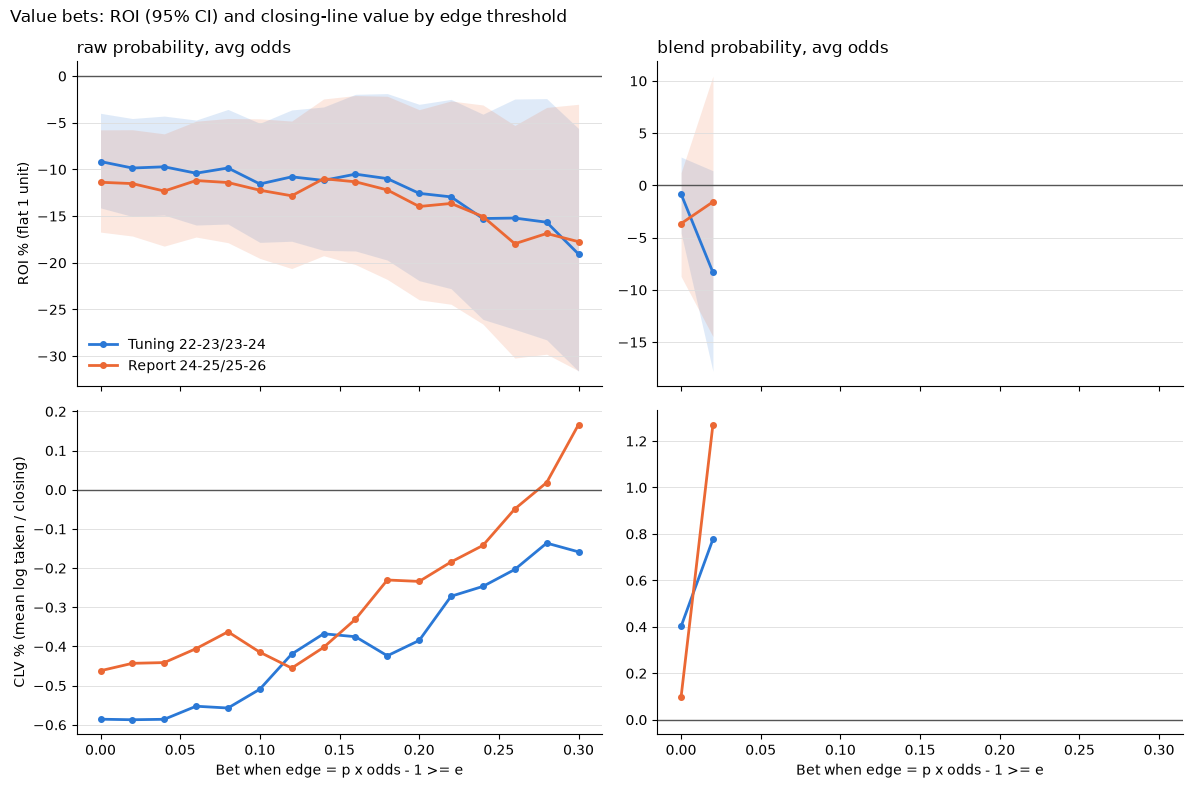

In [31]:
base = vresults[vresults["family"].isin(["value raw", "value blend"])].copy()
base["prob"] = base["variant"].str.split().str[0]
base["e"] = base["variant"].str.extract(r"e>=([\d.]+)")[0].astype(float)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for col, prob in enumerate(["raw", "blend"]):
    for period, colour, label in [("tune", TUNE_COLOUR, "Tuning 22-23/23-24"), ("report", REPORT_COLOUR, "Report 24-25/25-26")]:
        d = base[(base["prob"] == prob) & (base["source"] == "avg") & (base["period"] == period) & (base["bets"] >= 30)].sort_values("e")
        axes[0, col].fill_between(d["e"], d["roi_ci_low"], d["roi_ci_high"], color=colour, alpha=0.15, linewidth=0)
        axes[0, col].plot(d["e"], d["roi"], color=colour, linewidth=2, marker="o", markersize=4, label=label)
        axes[1, col].plot(d["e"], d["clv"], color=colour, linewidth=2, marker="o", markersize=4, label=label)
    axes[0, col].set_title(f"{prob} probability, avg odds", loc="left")
    axes[1, col].set_xlabel("Bet when edge = p x odds - 1 >= e")
for ax in axes.flat:
    ax.axhline(0, color="#555555", linewidth=1)
    ax.grid(axis="y", color="#dddddd", linewidth=0.6)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0, 0].set_ylabel("ROI % (flat 1 unit)")
axes[1, 0].set_ylabel("CLV % (mean log taken / closing)")
axes[0, 0].legend(frameon=False, loc="lower left")
fig.suptitle("Value bets: ROI (95% CI) and closing-line value by edge threshold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

In [32]:
def vcompact(families):
    rows = vresults[vresults["family"].isin(families)].copy()
    rows["roi [CI]"] = rows.apply(fmt, axis=1)
    wide = rows.pivot_table(index="variant", columns=["source", "period"], values="roi [CI]", aggfunc="first")
    bets = rows[rows["source"] == "avg"].pivot_table(index="variant", columns="period", values="bets_per_week")
    wide[("bets/wk", "tune")], wide[("bets/wk", "report")] = bets["tune"].round(1), bets["report"].round(1)
    clv = rows[rows["period"] == "report"].pivot_table(index="variant", columns="source", values="clv")
    wide[("CLV report", "avg")], wide[("CLV report", "max")] = clv["avg"].round(2), clv["max"].round(2)
    order = [("avg", "tune"), ("avg", "report"), ("avg", "26-27"), ("max", "tune"), ("max", "report"),
             ("bets/wk", "tune"), ("bets/wk", "report"), ("CLV report", "avg"), ("CLV report", "max")]
    return wide[[c for c in order if c in wide.columns]]

pd.concat({"raw": vcompact(["value raw"]), "blend": vcompact(["value blend"])})

source                                        avg                                                                  max                          bets/wk        CLV report       
period                                       tune                 report                26-27                     tune                   report    tune report        avg    max
      variant                                                                                                                                                                   
raw   raw e>=0.00 odds any     -9.2 [-14.1, -4.0]    -11.4 [-16.7, -5.8]   -8.9 [-20.5, +4.6]       -5.2 [-10.6, +0.4]       -5.9 [-11.0, -0.5]    57.8   55.4      -0.46  -0.82
      raw e>=0.02 odds any     -9.8 [-15.0, -4.5]    -11.5 [-17.1, -5.7]   -7.8 [-19.8, +6.6]       -4.9 [-10.4, +0.7]       -6.8 [-12.0, -1.4]    54.0   50.9      -0.44  -0.82
      raw e>=0.04 odds any     -9.7 [-14.9, -4.3]    -12.3 [-18.2, -6.2]   -6.4 [-19.3, +8.7]       -4.5 [-10.1, +1.3]       -6.6 [-12.2, -0.9]    49.9   46.3      -0.44  -0.77
      raw e>=0.06 odds any    -10.4 [-16.0, -4.7]    -11.2 [-17.2, -4.8]  -4.7 [-18.5, +10.6]       -5.3 [-10.9, +0.7]       -6.6 [-12.3, -0.7]    45.8   41.1      -0.41  -0.77
      raw e>=0.08 odds any     -9.8 [-15.8, -3.6]    -11.4 [-17.8, -4.5]  -4.9 [-21.0, +13.2]       -5.2 [-11.1, +1.0]       -7.4 [-13.5, -1.1]    42.0   36.8      -0.36  -0.74
      raw e>=0.10 odds any    -11.6 [-17.8, -5.1]    -12.2 [-19.5, -4.6]  -4.3 [-23.3, +16.4]       -5.0 [-11.2, +1.5]       -6.5 [-12.9, +0.2]    38.3   32.8      -0.41  -0.67
      raw e>=0.12 odds any    -10.8 [-17.7, -3.6]    -12.8 [-20.6, -4.8]  -0.5 [-20.4, +22.3]       -5.8 [-12.6, +1.1]       -7.3 [-14.5, +0.2]    35.0   29.6      -0.46  -0.71
      raw e>=0.14 odds any    -11.2 [-18.7, -3.3]    -11.0 [-19.2, -2.5]  +0.9 [-19.9, +25.8]       -5.7 [-12.5, +1.2]       -9.1 [-16.6, -0.9]    31.3   26.4      -0.40  -0.75
      raw e>=0.16 odds any    -10.5 [-18.7, -2.0]    -11.3 [-20.2, -2.1]  -2.6 [-22.9, +22.1]       -6.2 [-13.4, +1.3]       -8.9 [-16.8, -0.4]    28.5   23.5      -0.33  -0.75
      raw e>=0.18 odds any    -11.0 [-19.7, -1.9]    -12.2 [-21.8, -2.2]  -1.8 [-23.6, +24.5]       -7.6 [-15.5, +0.6]       -8.3 [-16.6, +0.7]    26.1   20.8      -0.23  -0.70
      raw e>=0.20 odds any    -12.6 [-21.9, -3.0]    -14.0 [-24.0, -3.6]  -1.7 [-24.1, +26.3]       -6.3 [-14.8, +2.6]       -7.8 [-16.6, +1.7]    23.8   18.5      -0.23  -0.72
      raw e>=0.22 odds any    -12.9 [-22.8, -2.5]    -13.6 [-24.4, -2.7]  +1.4 [-22.1, +31.6]       -4.3 [-13.0, +4.8]       -7.5 [-17.2, +3.4]    21.2   16.3      -0.18  -0.50
      raw e>=0.24 odds any    -15.3 [-26.1, -4.1]    -15.0 [-26.6, -3.1]  +1.5 [-22.4, +33.8]       -4.5 [-13.3, +4.5]       -7.3 [-17.4, +3.8]    19.2   14.8      -0.14  -0.49
      raw e>=0.26 odds any    -15.2 [-27.1, -2.5]    -18.0 [-30.2, -5.3]  +2.4 [-22.5, +39.4]       -4.9 [-14.5, +5.0]       -8.3 [-19.2, +3.8]    17.4   13.2      -0.05  -0.39
      raw e>=0.28 odds any    -15.7 [-28.3, -2.4]    -16.9 [-29.8, -3.4]  +0.1 [-24.9, +38.1]       -4.4 [-15.6, +6.7]       -7.8 [-19.3, +4.8]    15.9   11.7       0.02  -0.29
      raw e>=0.30 odds any    -19.1 [-31.6, -5.6]    -17.7 [-31.6, -3.0]  +2.1 [-22.8, +40.1]       -6.8 [-18.7, +5.4]      -10.1 [-21.9, +2.9]    14.5   10.7       0.17  -0.20
blend blend e>=0.00 odds any    -0.8 [-4.5, +2.7]      -3.7 [-8.7, +1.2]  -5.4 [-65.8, +42.0]        +3.7 [+0.8, +6.6]        -2.8 [-6.1, +0.3]    28.1   16.1       0.10  -0.41
      blend e>=0.02 odds any   -8.3 [-17.8, +1.4]    -1.6 [-14.5, +10.5]    +nan [+nan, +nan]        +2.8 [-0.2, +6.0]        -0.6 [-5.5, +4.0]     4.6    2.1       1.27   0.16
      blend e>=0.04 odds any  -0.7 [-54.4, +55.5]  -20.1 [-100.0, +74.0]    +nan [+nan, +nan]       +3.5 [-3.1, +10.5]        +0.1 [-8.4, +8.7]     0.2    0.1       5.43   1.46
      blend e>=0.06 odds any    +nan [+nan, +nan]   +67.0 [+67.0, +67.0]    +nan [+nan, +nan]      +2.7 [-

### Does the predicted edge show up in the results?

Every (match, outcome) pair in the test seasons, bucketed by its raw-model edge at
avg odds: if the edges were real, realised ROI would rise with predicted edge.

In [33]:
pairs = pd.DataFrame({
    "period": np.repeat(np.where(PERIOD_MASK["tune"], "tune", np.where(PERIOD_MASK["report"], "report", "26-27")), 3),
    "p": P_MODEL.ravel(), "b": P_BLEND.ravel(), "q": Q.ravel(),
    "odds": ODDS3["avg"].ravel(), "hit": (Y[:, None] == np.arange(3)).ravel(),
})
pairs = pairs[np.isfinite(pairs["odds"])]
pairs["return"] = np.where(pairs["hit"], pairs["odds"] - 1, -1.0)
edge_bins = [-1, -0.10, -0.05, 0, 0.05, 0.10, 0.20, 0.30, 10]
edge_labels = ["< -10", "-10..-5", "-5..0", "0..5", "5..10", "10..20", "20..30", "> 30"]
out = {}
for prob in ["p", "b"]:
    pairs["bucket"] = pd.cut(pairs[prob] * pairs["odds"] - 1, edge_bins, labels=edge_labels)
    g = pairs[pairs["period"] != "26-27"].groupby(["bucket", "period"], observed=True)
    out[{"p": "raw", "b": "blend"}[prob]] = pd.DataFrame({
        "n": g.size(), "mean predicted edge %": g.apply(lambda d: (d[prob] * d["odds"] - 1).mean() * 100),
        "actual hit %": g["hit"].mean() * 100, f"mean {prob} %": g[prob].mean() * 100,
        "mean q %": g["q"].mean() * 100, "ROI %": g["return"].mean() * 100,
    })
pd.concat(out).unstack("period").round(1)

n         mean predicted edge %       actual hit %        mean p %       mean q %        ROI %        mean b %      
period         report    tune                report  tune       report   tune   report  tune   report  tune report   tune   report  tune
      bucket                                                                                                                            
raw   < -10    6032.0  5636.0                 -22.3 -20.5         34.3   36.7     28.3  31.1     33.5  37.0   -6.1   -8.3      NaN   NaN
      -10..-5  1825.0  1895.0                  -7.6  -7.6         38.4   38.4     37.4  35.2     38.3  36.4   -6.1   -2.4      NaN   NaN
      -5..0    1489.0  1475.0                  -2.5  -2.6         37.7   34.4     38.2  36.2     37.0  35.6   -4.5  -10.1      NaN   NaN
      0..5     1208.0  1130.0                   2.4   2.4         34.5   34.7     38.4  36.5     35.5  34.1  -10.3   -6.5      NaN   NaN
      5..10     939.0   898.0                   7.3   7.4         32.2   33.6     38.5  35.9     33.9  31.8  -11.1   -0.7      NaN   NaN
      10..20   1203.0  1314.0                  14.6  14.5         29.6   28.8     37.5  35.4     30.8  29.5   -9.3  -10.5      NaN   NaN
      20..30    637.0   809.0                  24.3  24.4         26.7   27.2     36.0  34.7     27.2  26.5   -8.8   -0.1      NaN   NaN
      > 30      851.0  1249.0                  51.7  55.8         17.7   16.6     30.7  29.2     19.6  18.3  -19.3  -18.4      NaN   NaN
blend < -10    5054.0  4255.0                 -15.8 -16.1         18.4   15.2      NaN   NaN     18.9  17.3  -13.0  -19.6     17.4  15.8
      -10..-5  4225.0  4474.0                  -7.6  -7.4         29.9   27.1      NaN   NaN     29.4  27.7   -3.8   -6.4     28.7  26.9
      -5..0    3669.0  3514.0                  -2.3  -2.2         49.7   47.3      NaN   NaN     49.6  45.1   -6.6    0.8     51.4  46.2
      0..5     1233.0  2162.0                   1.1   1.2         57.7   59.2      NaN   NaN     57.6  57.4   -3.8   -0.9     60.6  60.1
      5..10       2.0     1.0                   5.4   5.7         50.0  100.0      NaN   NaN     47.1  44.2   24.0  123.0     49.6  47.4
      10..20      1.0     NaN                  11.2   NaN        100.0    NaN      NaN   NaN     63.5   NaN   67.0    NaN     66.6   NaN

### Odds bands and the sharp-line filter

ROI % at avg (flat 1u) for a few edge thresholds. Tuning / report / 26-27.

In [34]:
grid = vresults[vresults["family"].str.startswith("value") & (vresults["source"] == "avg")].copy()
parts = grid["variant"].str.extract(r"^(\w+) e>=([\d.]+) odds (\S+)( sharp)?$")
grid["prob"], grid["e"], grid["band"], grid["sharp"] = parts[0], parts[1].astype(float), parts[2], parts[3].notna()
sub = grid[grid["e"].isin([0.0, 0.04, 0.10, 0.20])]
print("ROI % at avg")
display(sub.pivot_table(index=["prob", "sharp", "band"], columns=["e", "period"], values="roi")
        .reindex(columns=["tune", "report", "26-27"], level=1).round(1))
print("Bets per week, tuning seasons")
sub[sub["period"] == "tune"].pivot_table(index=["prob", "sharp", "band"], columns="e", values="bets_per_week").round(1)

ROI % at avg


e                   0.00               0.04               0.10               0.20             
period              tune report 26-27  tune report 26-27  tune report 26-27  tune report 26-27
prob  sharp band                                                                              
blend False 1.5-3.0 -1.8   -3.8  -5.4  -0.7  -20.1   NaN   NaN   67.0   NaN   NaN    NaN   NaN
            1.5-5.0 -1.8   -3.8  -5.4  -0.7  -20.1   NaN   NaN   67.0   NaN   NaN    NaN   NaN
            2.0-4.0 -4.9    0.3   2.2 -12.2   18.0   NaN   NaN    NaN   NaN   NaN    NaN   NaN
            <=2.5   -0.8   -3.4  -5.4  -0.7   -8.7   NaN   NaN   67.0   NaN   NaN    NaN   NaN
            any     -0.8   -3.7  -5.4  -0.7  -20.1   NaN   NaN   67.0   NaN   NaN    NaN   NaN
      True  1.5-3.0 -4.5   -3.5  -5.4  -0.7  -32.6   NaN   NaN    NaN   NaN   NaN    NaN   NaN
            1.5-5.0 -4.5   -3.5  -5.4  -0.7  -32.6   NaN   NaN    NaN   NaN   NaN    NaN   NaN
            2.0-4.0 -7.2    2.8   2.2 -12.2   18.0   NaN   NaN    NaN   NaN   NaN    NaN   NaN
            <=2.5   -3.8   -4.9  -5.4  -0.7  -21.3   NaN   NaN    NaN   NaN   NaN    NaN   NaN
            any     -3.7   -5.2  -5.4  -0.7  -32.6   NaN   NaN    NaN   NaN   NaN    NaN   NaN
raw   False 1.5-3.0 -2.1   -9.2  -6.1  -2.4  -10.1  -1.9  -3.6  -11.6   0.1  -7.7  -13.5  -0.9
            1.5-5.0 -5.2   -9.3  -9.1  -6.1  -10.2  -7.1  -8.2   -9.1  -6.2  -9.6   -5.1   4.7
            2.0-4.0 -2.3  -12.1  -6.7  -3.3  -12.6  -2.2  -4.7  -12.3  -2.6  -6.9   -6.9  -3.4
            <=2.5   -2.0   -6.2   5.3  -3.5   -6.1  11.0  -4.7   -6.2  10.5  -9.6   -4.9   3.8
            any     -9.2  -11.4  -8.9  -9.7  -12.3  -6.4 -11.6  -12.2  -4.3 -12.6  -14.0  -1.7
      True  1.5-3.0 -2.1   -9.2  -6.1  -2.4  -10.1  -1.9  -3.6  -11.6   0.1  -7.7  -13.5  -0.9
            1.5-5.0 -5.2   -9.3  -9.1  -6.1  -10.2  -7.1  -8.2   -9.1  -6.2  -9.6   -5.1   4.7
            2.0-4.0 -2.3  -12.1  -6.7  -3.3  -12.6  -2.2  -4.7  -12.3  -2.6  -6.9   -6.9  -3.4
            <=2.5   -2.0   -6.2   5.3  -3.5   -6.1  11.0  -4.7   -6.2  10.5  -9.6   -4.9   3.8
            any     -9.2  -11.4  -8.9  -9.7  -12.3  -6.4 -11.6  -12.2  -4.3 -12.6  -14.0  -1.7

Bets per week, tuning seasons


e                    0.00  0.04  0.10  0.20
prob  sharp band                           
blend False 1.5-3.0  20.4   0.2   0.0   0.0
            1.5-5.0  20.5   0.2   0.0   0.0
            2.0-4.0   6.3   0.1   0.0   0.0
            <=2.5    27.3   0.2   0.0   0.0
            any      28.1   0.2   0.0   0.0
      True  1.5-3.0  13.9   0.2   0.0   0.0
            1.5-5.0  14.0   0.2   0.0   0.0
            2.0-4.0   5.8   0.1   0.0   0.0
            <=2.5    14.3   0.2   0.0   0.0
            any      15.1   0.2   0.0   0.0
raw   False 1.5-3.0  24.3  19.2  12.6   5.6
            1.5-5.0  46.5  38.2  26.4  12.7
            2.0-4.0  28.6  23.8  17.5   9.4
            <=2.5    16.6  12.2   7.2   2.6
            any      57.8  49.9  38.3  23.8
      True  1.5-3.0  24.3  19.2  12.6   5.6
            1.5-5.0  46.5  38.2  26.4  12.7
            2.0-4.0  28.6  23.8  17.5   9.4
            <=2.5    16.6  12.2   7.2   2.6
            any      57.8  49.9  38.3  23.8

In [35]:
# CLV vs ROI across all grid variants, report seasons: does a rule with positive CLV make money?
rep = grid[(grid["period"] == "report") & (grid["bets"] >= MIN_TUNE_BETS)]
print(f"{len(rep)} grid variants at avg with >= {MIN_TUNE_BETS} report bets; "
      f"positive CLV: {(rep['clv'] > 0).sum()}, positive ROI: {(rep['roi'] > 0).sum()}")
print("Best report-season CLV (for information, not a selection):")
rep.sort_values("clv", ascending=False)[["variant", "bets", "roi", "roi_ci_low", "roi_ci_high", "clv"]].head(8).round(2)

160 grid variants at avg with >= 150 report bets; positive CLV: 22, positive ROI: 3
Best report-season CLV (for information, not a selection):


,variant,bets,roi,roi_ci_low,roi_ci_high,clv
1965,blend e>=0.00 odds 2.0-4.0 sharp,197,2.85,-13.68,19.85,1.43
1959,blend e>=0.00 odds 2.0-4.0,206,0.33,-15.75,16.81,1.34
1983,blend e>=0.02 odds any,165,-1.58,-14.46,10.46,1.27
2031,blend e>=0.02 odds <=2.5,162,0.25,-12.53,11.93,1.19
1941,blend e>=0.00 odds 1.5-5.0 sharp,722,-3.48,-11.54,4.79,0.20
1953,blend e>=0.00 odds 1.5-3.0 sharp,722,-3.48,-11.54,4.79,0.20
1863,raw e>=0.30 odds any,826,-17.74,-31.57,-3.02,0.17
1869,raw e>=0.30 odds any sharp,826,-17.74,-31.57,-3.02,0.17


### Tuning vs report across all value variants

In [36]:
vwide = vresults[(vresults["source"] == "avg")].pivot_table(index=["family", "variant"], columns="period", values=["roi", "bets"])
vwide = vwide[(vwide[("bets", "tune")] >= MIN_TUNE_BETS) & (vwide[("bets", "report")] >= MIN_TUNE_BETS)]
print(f"{len(vwide)} variants with >= {MIN_TUNE_BETS} bets in both periods")
print(f"Correlation tuning vs report ROI: {vwide[('roi', 'tune')].corr(vwide[('roi', 'report')]):+.2f}")
print(f"Positive in tuning: {(vwide[('roi', 'tune')] > 0).sum()}; positive in report: {(vwide[('roi', 'report')] > 0).sum()};"
      f" positive in both: {((vwide[('roi', 'tune')] > 0) & (vwide[('roi', 'report')] > 0)).sum()}")
vwide.sort_values(("roi", "tune"), ascending=False).head(10)["roi"][["tune", "report", "26-27"]].round(2)

160 variants with >= 150 bets in both periods
Correlation tuning vs report ROI: +0.21
Positive in tuning: 0; positive in report: 3; positive in both: 0


period                                                   tune  report  26-27
family                   variant                                            
value blend + band       blend e>=0.00 odds <=2.5       -0.76   -3.42  -5.40
value blend              blend e>=0.00 odds any         -0.82   -3.65  -5.40
value raw + band + sharp raw e>=0.08 odds 1.5-3.0 sharp -1.55  -10.02   0.91
value raw + band         raw e>=0.08 odds 1.5-3.0       -1.55  -10.02   0.91
value blend + band       blend e>=0.00 odds 1.5-5.0     -1.76   -3.76  -5.40
                         blend e>=0.00 odds 1.5-3.0     -1.77   -3.76  -5.40
value raw + band         raw e>=0.00 odds <=2.5         -2.00   -6.16   5.27
value raw + band + sharp raw e>=0.00 odds <=2.5 sharp   -2.00   -6.21   5.27
                         raw e>=0.02 odds 1.5-3.0 sharp -2.06   -9.47  -4.16
value raw + band         raw e>=0.02 odds 1.5-3.0       -2.06   -9.47  -4.16

In [37]:
# Pre-registered P8-02 hypothesis (found on all seasons in P8-02, so no period here is clean out-of-sample)
vshow(*HYPOTHESIS)

bets  bets_per_week  hit_rate  avg_odds  mean_edge    roi  roi_ci_low  roi_ci_high   clv
avg  tune     187           2.43     64.71      1.77     -28.80   7.36       -6.28        20.87 -1.48
     report    81           1.05     59.26      1.87     -29.57   6.01      -13.85        25.93 -1.34
     26-27     36           3.27     58.33      1.73     -30.13  -4.72      -30.20        20.80 -1.08
b365 tune     187           2.43     64.71      1.76     -29.32   6.37       -7.15        19.71 -1.60
     report    81           1.05     59.26      1.86     -29.59   5.59      -14.12        25.44 -1.08
     26-27     36           3.27     58.33      1.74     -29.67  -3.97      -29.48        21.84 -0.46
max  tune     187           2.43     64.71      1.83     -26.65  10.57       -3.42        24.41 -2.21
     report    81           1.05     59.26      1.92     -27.52   9.17      -11.27        29.59 -1.79
     26-27     36           3.27     58.33      1.80     -27.54  -1.61      -28.43        25.54 -0.97

## Staking

The chosen rule under each staking plan, on a simulated 100u bankroll at avg
odds. Kelly and the proportional plans size with the probability the rule
selected with (raw or blended). For contrast, the same plans also run on a
"naive" raw-model value rule (edge >= 0.05, any odds, no filter).

- **flat** 1u a bet;
- **proportional to edge** 10u x edge (1u at a 10% edge);
- **fixed %** 1% of the current bankroll a bet;
- **¼ Kelly, ½ Kelly**: each bet capped at 5% of the bankroll, the week's total at 20%.

Each season starts at 100u; "tune" and "report" run their two seasons as one
continuous bankroll. Risk of ruin = share of 5,000 bootstrap paths (weeks
resampled) that fall to 20u or below: weekly growth factors for the
bankroll-share plans, weekly unit profits for flat and proportional.

In [38]:
PLANS = {
    "flat 1u": (flat_plan(1.0), False),
    "10u x edge": (edge_plan(10.0), False),
    "1% of bankroll": (percent_plan(0.01), True),
    "1/4 Kelly": (kelly_plan(0.25, 0.05, 0.20), True),
    "1/2 Kelly": (kelly_plan(0.50, 0.05, 0.20), True),
}
NAIVE_ARGS = ("raw", 0.04, "any", False)
STAKE_RULES = {f"chosen: {VCHOSEN[1]}": VCHOSEN_ARGS, f"naive: {variant_name(*NAIVE_ARGS)}": NAIVE_ARGS}
STAKE_PERIODS = {**{s: [s] for s in TEST + [CURRENT]}, "tune": TUNE, "report": REPORT}

RUNS, rows = {}, []
for rule_name, args in STAKE_RULES.items():
    rule = week_rule(*args)
    for plan_name, (plan, multiplicative) in PLANS.items():
        strategy = value_strategy(rule, plan, p_columns=rule.p_columns)
        for period, seasons in STAKE_PERIODS.items():
            res = simulate(oos[oos["Season"].isin(seasons)], strategy, source="avg", bankroll=100.0)
            RUNS[(rule_name, plan_name, period)] = res
            summ = summarise(res).loc["overall"]
            rows.append({"rule": rule_name, "plan": plan_name, "period": period,
                         **bankroll_stats(res, level=0.2, multiplicative=multiplicative),
                         "roi_ci_low": summ["roi_ci_low"], "roi_ci_high": summ["roi_ci_high"], "clv": summ["clv"],
                         "hit_rate": summ["hit_rate"], "avg_odds": summ["avg_odds"], "weeks": summ["weeks"]})
stakes = pd.DataFrame(rows)
stake_cols = ["bets", "staked", "roi", "roi_ci_low", "roi_ci_high", "clv", "final_bankroll", "min_bankroll",
              "max_drawdown", "max_drawdown_pct", "worst_week", "risk_of_ruin"]
stakes.set_index(["rule", "plan", "period"])[stake_cols].round(1)

bets  staked   roi  roi_ci_low  roi_ci_high  clv  final_bankroll  min_bankroll  max_drawdown  max_drawdown_pct  worst_week  risk_of_ruin
rule                             plan           period                                                                                                                                          
chosen: blend e>=0.00 odds <=2.5 flat 1u        22-23    995   995.0  -1.2        -6.9          4.3  0.4            88.1          82.2          28.9              25.6       -11.6           1.6
                                                23-24   1107  1107.0  -0.4        -4.8          3.8  0.3            95.9          82.2          30.0              26.7       -11.1           0.2
                                                24-25    981   981.0  -3.2        -8.8          2.2  0.1            68.7          66.6          55.8              45.6       -11.1           4.6
                                                25-26    241   241.0  -4.4       -13.4          4.1  0.2            89.5          89.5          13.7              13.3        -4.8           0.0
                                                26-27     10    10.0  -5.4       -65.8         42.0  0.9            99.5          99.5           2.0               2.0        -1.0           0.0
                                                tune    2102  2102.0  -0.8        -4.3          2.7  0.4            83.9          70.3          42.8              37.8       -11.6           6.9
                                                report  1222  1222.0  -3.4        -8.3          1.1  0.1            58.2          58.2          64.2              52.4       -11.1          11.9
                                 10u x edge     22-23    995   116.6  -3.9       -11.4          3.3  0.4            95.5          95.2           6.1               6.1        -2.0           0.0
                                                23-24   1107   130.1  -1.8        -7.9          4.2  0.3            97.6          95.7           5.2               5.2        -1.3           0.0
                                                24-25    981   111.6  -3.0        -9.2          3.0  0.1            96.6          96.3           6.5               6.4        -1.1           0.0
                                                25-26    241    21.5  -4.7       -17.4          8.4  0.2            99.0          98.9           1.2               1.2        -0.7           0.0
                                                26-27     10     0.5 -33.9       -91.5         45.9  0.9            99.8          99.8           0.2               0.2        -0.2           0.0
                                                tune    2102   246.7  -2.8        -7.6          1.9  0.4            93.1          91.2          10.1              10.0        -2.0           0.0
                                                report  1222   133.2  -3.3        -9.0          2.4  0.1            95.6          95.5           7.3               7.1        -1.1           0.0
                                 1% of bankroll 22-23    995   935.1  -1.6        -7.4          4.2  0.4            85.2          81.9          30.2              26.9       -11.4           0.0
                                                23-24   1107  1069.2  -0.6        -5.1          3.6  0.3            93.2          81.9          29.8              26.7       -11.4           0.0
                                                24-25    981   940.1  -3.1        -9.1          2.5  0.1            70.4          68.9          54.2              44.0       -13.6           0.0
                                                25-26    241   234.7  -4.5       -13.4          3.9  0.2            89.5          89.5          13.7              13.3        -4.9           0.0
                                                26-27     10    10.0  -5.7       -66.1         42.0  0.9            99.4          99.4           2.1               2.0        -1.0           0.0
   

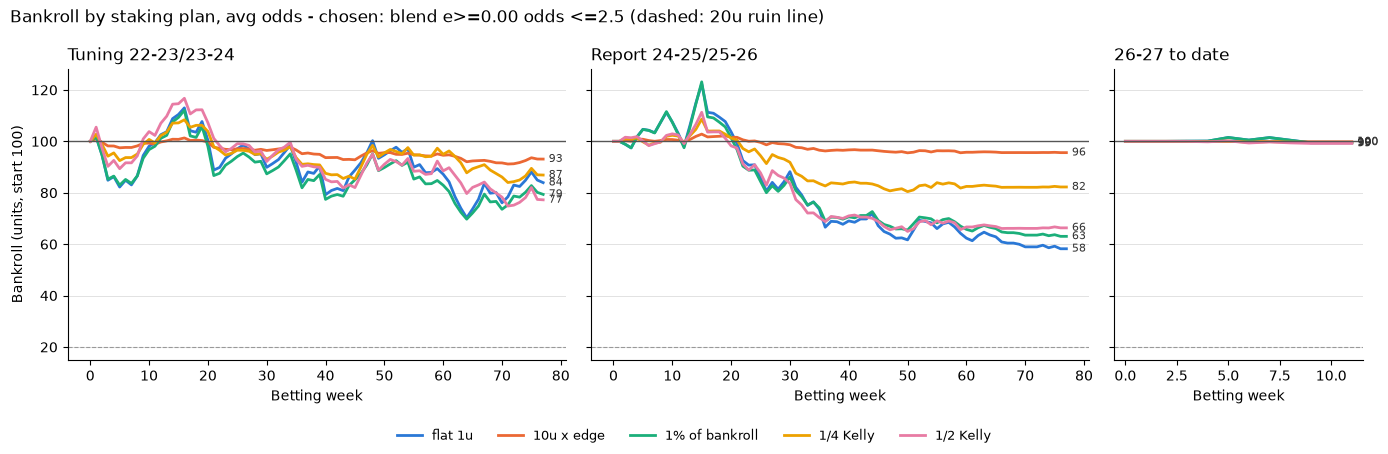

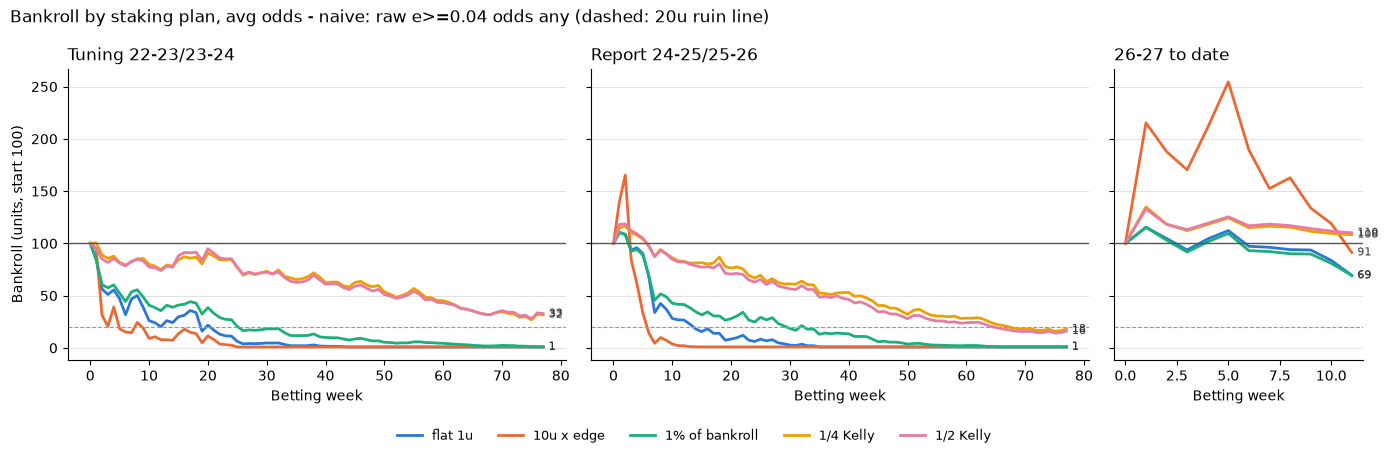

In [39]:
# Bankroll curves, chosen rule: tuning and report seasons (continuous), 26-27 to date
PLAN_COLOURS = dict(zip(PLANS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
for rule_name in STAKE_RULES:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True, gridspec_kw={"width_ratios": [2, 2, 1]})
    for ax, period, title in zip(axes, ["tune", "report", CURRENT], ["Tuning 22-23/23-24", "Report 24-25/25-26", "26-27 to date"]):
        for plan_name in PLANS:
            path = np.concatenate([[100.0], bankroll_path(RUNS[(rule_name, plan_name, period)]).to_numpy()])
            ax.plot(np.arange(len(path)), path, color=PLAN_COLOURS[plan_name], linewidth=2, label=plan_name)
            ax.annotate(f"{path[-1]:.0f}", (len(path) - 1, path[-1]), xytext=(4, 0), textcoords="offset points",
                        fontsize=8, va="center", color="#333333")
        ax.axhline(100, color="#555555", linewidth=1)
        ax.axhline(20, color="#999999", linewidth=0.8, linestyle="--")
        ax.set_title(title, loc="left")
        ax.set_xlabel("Betting week")
        ax.grid(axis="y", color="#dddddd", linewidth=0.6)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    axes[0].set_ylabel("Bankroll (units, start 100)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, loc="lower center", ncol=len(PLANS), fontsize=9)
    fig.suptitle(f"Bankroll by staking plan, avg odds - {rule_name} (dashed: 20u ruin line)", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()

## P8-04 variant log

In [40]:
stake_log = stakes.assign(
    family="staking",
    variant=stakes["rule"] + " | " + stakes["plan"],
    source="avg",
    bets_per_week=stakes["bets"] / stakes["weeks"],
)
stake_log = stake_log[stake_log["period"].isin(PERIODS)]
log = log_variants(pd.concat([vresults.drop(columns=["profit", "mean_edge"]), stake_log], ignore_index=True), ticket="P8-04")
n_sel = vresults.groupby(["family", "variant"]).ngroups
n_stake = stake_log.groupby("variant").ngroups
print(f"Logged {n_sel} P8-04 selection variants + {n_stake} staking runs; log now holds",
      log.groupby("ticket")["variant"].nunique().to_dict())

Logged 321 P8-04 selection variants + 10 staking runs; log now holds {'P8-03': 274, 'P8-04': 331, 'P8-05': 67, 'P8-06': 134}


In [41]:
# For P8-07: weekly P&L of every P8-04 selection variant and the chosen rule's bets
weekly, bets = [], []
for (key, source), (sel, edge) in SELECTIONS.items():
    bet = sel >= 0
    s = sel[bet]
    odds, closing = ODDS3[source][ROWS[bet], s], CLOSE3[source][ROWS[bet], s]
    profit = np.where(Y[bet] == s, odds - 1, -1.0)
    weekly.append(weekly_pnl(WEEK_LABEL[bet], profit).assign(family=key[0], variant=key[1], source=source))
    if key == VCHOSEN:
        bets.append(chosen_frame(key[1], source, bet, np.array(OUTCOMES)[s], odds, closing, profit))
weekly = pd.concat(weekly, ignore_index=True)
check_totals(weekly, vresults)
log_variant_weeks(weekly, ticket="P8-04")
log_chosen_bets(pd.concat(bets, ignore_index=True), ticket="P8-04")
print(f"Weekly P&L logged for {weekly.groupby(['family', 'variant']).ngroups} variants; chosen-rule bets:",
      pd.concat(bets).groupby("source").size().to_dict())

Weekly P&L logged for 321 variants; chosen-rule bets: {'avg': 3334, 'b365': 2618, 'max': 7161}


## P8-04 findings

**Verdict: value betting doesn't make money, and no staking plan fixes that.** With
the raw model, value bets lose more than backing its pick. With the blended
probability, which is almost the market, the edges are tiny, rare and only exist
where Pinnacle prices are in the data. Kelly only loses less because it stakes less.

- **Chosen rule (pre-registered):** blended probability, edge >= 0, odds <= 2.5.
  Tuning -0.8% [-4.3, +2.7] at avg (2,102 bets, 27/week, CLV +0.37). **Report -3.4%
  [-8.3, +1.1]** (1,222 bets, CLV +0.08), 26-27 to date -5.4% on 10 bets. At max:
  +2.5 -> -0.8 -> +7.0 (274 bets). It was the best of 168 eligible tuning variants,
  and **none of the 168 was positive in tuning at avg.**
- **The blended rule is really "the average price is longer than Pinnacle's fair
  price".** The blend is 8% model, so where Pinnacle is missing (q from Avg: half of
  25-26, all of 26-27) Avg prices never show an edge. 214 of 241 bets in 25-26 and 0
  of 10 in 26-27 had a Pinnacle q. The live pipeline has no Pinnacle prices for
  26-27, so this rule can't run as it stands. Blend edges above 2% are almost
  nonexistent at avg (0.2 bets/week at e >= 0.04).
- **Raw model edges are adverse selection.** Every raw edge threshold loses 9-19%
  in tuning and 11-18% in report seasons at avg, all CIs below 0, and worse than
  every argmax pick (-6.0%) or the market favourite (-3.8%). Bucketing every
  (match, outcome) by predicted edge, realised ROI is -6% to -19% whatever the edge
  is. In the > 30% bucket the model says 30.7%, the market 19.6%, actual 17.7%.
  CLV is negative (-0.6 to -0.4%) and only gets to ~0 at e >= 0.28.
- **Sharp-line filter (`p_model > q`):** changes nothing for raw edges at avg. A
  positive edge at an average price already implies p > q, because the average
  carries a margin. For blended edges it removes bets and makes them worse.
- **Odds bands** cut the raw-model losses (<= 2.5: -2.0% tune, -6.2% report),
  because long-shot "value" is model error, as expected. No band is positive in both periods.
- **Max odds:** blend e >= 0 at the best price was +3.7% [+0.8, +6.6] in tuning,
  -2.8% [-6.1, +0.3] in report. Best-price shopping against Pinnacle doesn't
  survive, and max prices aren't reliably available anyway.
- **CLV vs ROI:** of 160 grid variants with >= 150 report bets, 22 had positive CLV
  and 3 had positive ROI. The highest CLV (+1.4%, blend e >= 0 odds 2-4 sharp,
  197 bets) is too small a sample to mean anything.
- **Pre-registered P8-02 hypothesis** (away favourites, model > 10pp below the
  market): +7.4% [-6.3, +20.9] tune (187 bets), +6.0% [-13.9, +25.9] report (81),
  -4.7% 26-27 (36). CLV is **negative** (-1.3%) in every period, so the price moved
  against these bets. There's no evidence of a real edge, and no period is a clean
  test because P8-02 found the pattern by looking at all of them.
- **Overfitting check:** 160 variants with >= 150 bets in both periods. 0 positive
  in tuning, 3 in report, 0 in both. Tuning vs report ROI correlation +0.21, mostly
  the raw-vs-blend split.

**Staking (100u start, avg odds, report seasons 24-25/25-26 run as one bankroll):**

| Plan | Chosen rule: final | max DD | worst week | ruin < 20u | Naive raw e >= 0.04: final | ruin |
|---|---|---|---|---|---|---|
| flat 1u | 58.2 | 64.2u (52%) | -11.1 | 11.9% | 0.9 (bust) | 66% |
| 10u x edge | 95.6 | 7.3u (7%) | -1.1 | 0% | 1.0 (bust) | 63% |
| 1% of bankroll | 63.0 | 49% | -13.6 | 0% | 1.0 | 99.8% |
| 1/4 Kelly (5%/bet, 20%/wk) | 82.2 | 26% | -4.7 | 0% | 17.9 | 63% |
| 1/2 Kelly (5%/bet, 20%/wk) | 66.3 | 42% | -7.7 | 0% | 16.0 | 71% |

Tuning seasons, chosen rule: flat 83.9, edge 93.1, 1% 79.4, 1/4 Kelly 86.9,
1/2 Kelly 77.2. Every plan ends below 100 in both periods. Proportional and Kelly
plans lose less because they stake less (the chosen rule's edges average about
1%). The ROI is the same -3 to -4%. With the naive raw rule, at about 50 bets a week,
the 20% weekly cap binds, so 1/4 and 1/2 Kelly are nearly the same, and both lose
more than 80% of the bankroll.

331 P8-04 variants logged (321 selection + 10 staking runs). The log now holds 605.

# P8-05: Accumulators and multiples

Combine the week's picks into accumulators (one bet, wins only if every leg
wins, at the product of the odds) and system bets, and compare each with
staking **the same total as singles on the same legs**, which is the comparison
that matters. An acca compounds the margin (five legs at 5% each is about 23%),
so it only helps if each leg has a positive edge. P8-03/P8-04 found none, so the
prior is that accas lose more than singles and are far more volatile.

**Leg pools** (each ranked within the betting week):

| Pool | Legs | Ranked by |
|---|---|---|
| `p` | every priced argmax pick (optionally odds >= m, or p >= t) | model probability |
| `P8-03 rule` | P8-03's chosen rule (P1 picks, p >= 0.475) | model probability |
| `value` | P8-04's chosen value bets (blended p, edge >= 0, odds <= 2.5) | blended edge |

**Strategies** (1u per bet): top-k acca (k = 2..8, with and without a minimum
leg price), threshold acca (every pick with p >= t; skipped if fewer than 2
legs), value accas, all doubles / trebles from the top k, and system bets
(Trixie, Patent, Yankee, Lucky 15) on the top 3 or 4. A week with too few legs
is skipped. Results are complete matches only, so there are no void legs.

**Same-leg singles:** each week, the acca strategy's total stake split equally
across its distinct legs, 1 bet per leg. **Diff** = acca ROI - singles ROI,
with a paired week-bootstrap CI (the same resampled weeks for both).

**Selection rule, fixed before any results were computed:** among the P8-05
acca / system variants at `avg` odds in the tuning seasons, those that bet in at
least half of the tuning weeks; the one with the highest ROI (ties: more bets).
Its report-season result is recorded whatever it is. Promotions are
sensitivity only and never count towards the choice.

In [42]:
from itertools import combinations

from betting.simulate import N_BOOT, SEED, Bet, Leg

IDX = {"H": 0, "D": 1, "A": 2}
PICK_IDX = np.array([IDX[p] for p in PICK])
WEEK_CODE, WEEK_LABELS = pd.factorize(oos["Week"])  # oos is in kick-off order, so codes are chronological
SEASON_OF_WEEK = dict(zip(oos["Week"], oos["Season"]))
VSEL = {source: SELECTIONS[(VCHOSEN, source)] for source in SOURCES}
P803_RULE = VARIANTS[CHOSEN]
print("P8-03 rule:", CHOSEN[1], "| P8-04 rule:", VCHOSEN[1])

def pool(kind, source, t=None, min_odds=None):
    # Candidate legs for one source: match rows, selection index (H, D, A = 0, 1, 2), ranking score
    if kind == "value":
        sel, edge = VSEL[source]
        rows = np.flatnonzero(sel >= 0)
        return rows, sel[rows], edge[rows]
    ok = priced(source)
    if kind == "P8-03":
        ok = ok & P803_RULE(source)
    if t is not None:
        ok = ok & (CONF >= t)
    if min_odds is not None:
        ok = ok & (np.nan_to_num(ODDS[source]) >= min_odds)
    rows = np.flatnonzero(ok)
    return rows, PICK_IDX[rows], CONF[rows]

def by_week(rows, sel, score):
    # {week: [(row, sel), ...]} best score first, ties to the earlier kick-off
    df = pd.DataFrame({"row": rows, "sel": sel, "score": score, "code": WEEK_CODE[rows]})
    df = df.sort_values(["code", "score", "row"], ascending=[True, False, True])
    return {WEEK_LABELS[c]: list(zip(g["row"], g["sel"])) for c, g in df.groupby("code", sort=True)}

# --- Bet builders: the week's ranked legs -> [(stake, legs), ...] -----------
def acca_top(k):
    return lambda legs: [(1.0, tuple(legs[:k]))] if len(legs) >= k else []

def acca_all(min_legs=2):
    return lambda legs: [(1.0, tuple(legs))] if len(legs) >= min_legs else []

def multiples(k, sizes):
    # Every combination of each size from the top k legs, 1u each
    def build(legs):
        if len(legs) < k:
            return []
        return [(1.0, combo) for s in sizes for combo in combinations(legs[:k], s)]
    return build

SYSTEMS = {"Trixie": (3, [2, 3]), "Patent": (3, [1, 2, 3]), "Yankee": (4, [2, 3, 4]), "Lucky 15": (4, [1, 2, 3, 4])}
assert [len(multiples(k, s)(list(range(k)))) for k, s in SYSTEMS.values()] == [4, 7, 11, 15]

P8-03 rule: P1 p>=0.475 | P8-04 rule: blend e>=0.00 odds <=2.5


### Settlement

`settle()` builds a strategy's bets for every week at one source and settles
them: payout = stake x product of the leg odds if every leg won, else 0. Per
bet it also keeps the number of losing legs (for "one leg lets you down"), the
leg CLV, and the market's fair value of the bet, `prod(q * o)`, whose average
minus 1 is the ROI the de-margined market expects (the compounded margin).
Per week it keeps the acca profit and the same-leg singles profit.

In [43]:
POOL_CACHE = {}

def ranked_legs(spec, source):
    key = (spec, source)
    if key not in POOL_CACHE:
        kind, t, m = (spec + (None, None))[:3]
        POOL_CACHE[key] = by_week(*pool(kind, source, t, m))
    return POOL_CACHE[key]

def settle(spec, builder, source):
    o3, c3 = ODDS3[source], CLOSE3[source]
    bets, weeks = [], []
    for week, legs in ranked_legs(spec, source).items():
        placed = builder(legs)
        if not placed:
            continue
        distinct = set()
        for stake, combo in placed:
            r = np.array([leg[0] for leg in combo])
            s = np.array([leg[1] for leg in combo])
            o, c, won = o3[r, s], c3[r, s], Y[r] == s
            clv = np.log(o / c)[np.isfinite(c) & (c > 0)]
            odds = float(np.prod(o))
            payout = stake * odds if won.all() else 0.0
            bets.append((week, len(combo), stake, odds, payout, payout - stake, int((~won).sum()),
                         clv.sum(), len(clv), float(np.prod(Q[r, s] * o)) * stake))
            distinct.update(combo)
        staked = sum(stake for stake, _ in placed)
        r = np.array([leg[0] for leg in distinct])
        s = np.array([leg[1] for leg in distinct])
        o = o3[r, s]
        single_profit = np.where(Y[r] == s, o - 1, -1.0).sum() * staked / len(distinct)
        weeks.append((week, staked, single_profit, len(distinct)))
    B = pd.DataFrame(bets, columns=["Week", "legs", "stake", "odds", "payout", "profit", "lost_legs",
                                    "clv_sum", "clv_n", "fair_return"])
    W = pd.DataFrame(weeks, columns=["Week", "staked", "s_profit", "distinct_legs"]).set_index("Week")
    W["profit"] = B.groupby("Week")["profit"].sum()
    return B, W

In [44]:
def paired_boot(w, n=N_BOOT, seed=SEED):
    # Same draw as bootstrap_roi(): resample weeks; acca ROI - singles ROI on each resample
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(w), size=(n, len(w)))
    staked = w["staked"].to_numpy()[idx].sum(axis=1)
    diff = (w["profit"].to_numpy()[idx].sum(axis=1) - w["s_profit"].to_numpy()[idx].sum(axis=1))
    with np.errstate(invalid="ignore", divide="ignore"):
        diff = diff / staked
    return np.percentile(diff[staked > 0], [2.5, 97.5])

def season_profit_boot(w, period, n=N_BOOT, seed=SEED):
    # Season profit distribution: resample one season's worth of weeks from each season in the period
    rng = np.random.default_rng(seed)
    out = []
    for season in PERIODS[period]:
        p = w.loc[[wk for wk in w.index if SEASON_OF_WEEK[wk] == season], "profit"].to_numpy()
        if len(p):
            out.append(p[rng.integers(0, len(p), size=(n, len(p)))].sum(axis=1))
    return np.concatenate(out) if out else np.array([np.nan])

def longest_run(lost):
    longest = run = 0
    for x in lost:
        run = run + 1 if x else 0
        longest = max(longest, run)
    return longest

EMPTY = {"bets": 0, "bets_per_week": 0.0, "weeks_bet": 0, "hit_rate": np.nan, "avg_odds": np.nan, "avg_legs": np.nan,
         "roi": np.nan, "roi_ci_low": np.nan, "roi_ci_high": np.nan, "clv": np.nan, "profit": 0.0,
         "fair_roi": np.nan, "s_roi": np.nan, "s_ci_low": np.nan, "s_ci_high": np.nan,
         "diff": np.nan, "diff_ci_low": np.nan, "diff_ci_high": np.nan}

def acca_eval(B, W, period, volatility=False):
    weeks = PERIOD_WEEKS[period]
    b = B[B["Week"].isin(set(weeks))]
    if b.empty:
        return dict(EMPTY)
    w = W.reindex(weeks, fill_value=0.0)
    staked = b["stake"].sum()
    roi = bootstrap_roi(w)
    sroi = bootstrap_roi(w[["s_profit", "staked"]].rename(columns={"s_profit": "profit"}))
    d_low, d_high = paired_boot(w)
    out = {
        "bets": len(b), "bets_per_week": len(b) / len(weeks), "weeks_bet": int((w["staked"] > 0).sum()),
        "hit_rate": (b["payout"] > b["stake"]).mean() * 100, "avg_odds": b["odds"].mean(), "avg_legs": b["legs"].mean(),
        "roi": b["profit"].sum() / staked * 100, "roi_ci_low": roi["ci"][0] * 100, "roi_ci_high": roi["ci"][1] * 100,
        "clv": b["clv_sum"].sum() / b["clv_n"].sum() * 100 if b["clv_n"].sum() else np.nan,
        "profit": b["profit"].sum(), "fair_roi": (b["fair_return"].sum() / staked - 1) * 100,
        "s_roi": w["s_profit"].sum() / staked * 100, "s_ci_low": sroi["ci"][0] * 100, "s_ci_high": sroi["ci"][1] * 100,
        "diff": (b["profit"].sum() - w["s_profit"].sum()) / staked * 100,
        "diff_ci_low": d_low * 100, "diff_ci_high": d_high * 100,
    }
    if volatility:
        bet_weeks = w[w["staked"] > 0]
        cum = np.concatenate([[0.0], np.cumsum(w["profit"].to_numpy())])
        total = w["profit"].sum()
        seasons = season_profit_boot(w, period)
        s_seasons = season_profit_boot(w.assign(profit=w["s_profit"]), period)
        multi = b[b["legs"] >= 2]
        won = b["payout"] > b["stake"]
        winnings_multi = (b["payout"] - b["stake"])[won & (b["legs"] >= 2)].sum()
        winnings_5 = (b["payout"] - b["stake"])[won & (b["legs"] >= 5)].sum()
        refund_5 = b.loc[(b["legs"] >= 5) & (b["lost_legs"] == 1), "stake"].sum()
        out.update({
            "weeks_won_pct": (bet_weeks["profit"] > 0).mean() * 100,
            "longest_losing_run": longest_run(b["profit"] < 0),
            "longest_losing_weeks": longest_run(bet_weeks["profit"] < 0),
            "max_drawdown": float((np.maximum.accumulate(cum) - cum).max()),
            "best_week": w["profit"].max(),
            "best_week_share": w["profit"].max() / total * 100 if total > 0 else np.nan,
            "season_p_up": (seasons > 0).mean() * 100, "season_p5": np.percentile(seasons, 5),
            "season_p50": np.percentile(seasons, 50), "season_p95": np.percentile(seasons, 95),
            "s_season_p_up": (s_seasons > 0).mean() * 100,
            "s_season_p5": np.percentile(s_seasons, 5), "s_season_p95": np.percentile(s_seasons, 95),
            # Promotions (sensitivity only)
            "breakeven_boost_all": -b["profit"].sum() / winnings_multi * 100 if winnings_multi > 0 and total < 0 else np.nan,
            "breakeven_boost_5plus": -b["profit"].sum() / winnings_5 * 100 if winnings_5 > 0 and total < 0 else np.nan,
            "roi_boost10_5plus": (b["profit"].sum() + 0.10 * winnings_5) / staked * 100,
            "roi_refund_5plus": (b["profit"].sum() + refund_5) / staked * 100,
            "roi_refund_fb_5plus": (b["profit"].sum() + 0.7 * refund_5) / staked * 100,
            "multi_bets": len(multi),
        })
    return out

### Check: evaluator = simulator

A few strategies written as ordinary `simulate()` strategies (reading only the
week's own columns) must give exactly `settle()` + `acca_eval()`'s numbers on
the test seasons: an acca, a system, a doubles strategy, a threshold acca.

In [45]:
def p_pool_strategy(builder, t=None):
    def strategy(week, bankroll):
        picks, conf = argmax_picks(week)
        odds = np.array([week[f"o{p}"].iloc[i] for i, p in enumerate(picks)], dtype=float)
        ok = np.isfinite(odds) & (odds > 1)
        if t is not None:
            ok &= conf >= t
        ok = np.flatnonzero(ok)
        order = ok[np.argsort(-conf[ok], kind="stable")]
        keys = week["MatchKey"].to_numpy()
        legs = [(keys[i], picks[i]) for i in order]
        return [Bet([Leg(k, p) for k, p in combo], stake) for stake, combo in builder(legs)]
    return strategy

checks = [
    ("acca top 3", ("p",), acca_top(3), None),
    ("Yankee top 4", ("p",), multiples(*SYSTEMS["Yankee"]), None),
    ("doubles from top 4", ("p",), multiples(4, [2]), None),
    ("acca all p>=0.70", ("p", 0.70), acca_all(), 0.70),
]
rows = []
for name, spec, builder, t in checks:
    for source in SOURCES:
        sim = summarise(simulate(test, p_pool_strategy(builder, t), source=source)).loc["overall"]
        ev = acca_eval(*settle(spec, builder, source), "test")
        for metric in ["bets", "profit", "roi", "roi_ci_low", "roi_ci_high", "clv", "hit_rate"]:
            assert abs(round(ev[metric], 2) - sim[metric]) < 0.06, (name, source, metric, ev[metric], sim[metric])
        rows.append({"rule": name, "source": source, "bets": sim["bets"], "roi": sim["roi"],
                     "ci": f"[{sim['roi_ci_low']:+.2f}, {sim['roi_ci_high']:+.2f}]", "clv": sim["clv"]})
print("settle() + acca_eval() match simulate() on all checks")
pd.DataFrame(rows)

settle() + acca_eval() match simulate() on all checks


,rule,source,bets,roi,ci,clv
0,acca top 3,avg,151.0,8.77,"[-5.39, +22.47]",-0.20
1,acca top 3,b365,151.0,9.14,"[-5.04, +22.86]",-0.25
2,acca top 3,max,151.0,16.04,"[+0.92, +30.76]",-0.69
3,Yankee top 4,avg,1661.0,-1.92,"[-12.38, +9.00]",-0.21
4,Yankee top 4,b365,1661.0,-1.73,"[-12.24, +9.15]",-0.20
5,Yankee top 4,max,1661.0,3.76,"[-7.32, +15.37]",-0.67
6,doubles from top 4,avg,906.0,-1.76,"[-9.96, +6.73]",-0.21
7,doubles from top 4,b365,906.0,-1.65,"[-9.85, +6.81]",-0.20
8,doubles from top 4,max,906.0,2.71,"[-5.85, +11.50]",-0.67
9,acca all p>=0.70,avg,139.0,4.82,"[-22.52, +35.30]",-0.12


### Are same-week legs independent?

An acca's price assumes its legs are independent. Standardised residuals
`z = (won - q) / sqrt(q (1 - q))` for every argmax pick (q = de-margined market
probability of the pick), and the mean `z_i z_j` over pairs of picks in the same
betting week, which is their correlation. Split by same league + same day, same
league + different day, and different leagues. CI from resampling weeks.

In [46]:
q_pick = Q[np.arange(len(oos)), PICK_IDX]
z = (WON.astype(float) - q_pick) / np.sqrt(q_pick * (1 - q_pick))
pairs_df = pd.DataFrame({"Week": oos["Week"], "Div": oos["Div"], "Day": oos["MatchDateTime"].dt.date, "z": z})

def cross(groups):
    # Per week: sum of z_i z_j over pairs within each group, and the number of pairs
    g = pairs_df.groupby(["Week"] + groups)["z"].agg(s="sum", s2=lambda x: (x ** 2).sum(), n="count")
    g["cross"], g["pairs"] = (g["s"] ** 2 - g["s2"]) / 2, g["n"] * (g["n"] - 1) / 2
    return g.groupby("Week")[["cross", "pairs"]].sum()

all_pairs, same_league, same_day = cross([]), cross(["Div"]), cross(["Div", "Day"])
parts = {
    "same league, same day": same_day,
    "same league, other day": same_league - same_day,
    "different leagues": all_pairs - same_league,
    "all same-week pairs": all_pairs,
}
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(all_pairs), size=(N_BOOT, len(all_pairs)))
rows = {}
for name, part in parts.items():
    c, n = part["cross"].to_numpy(), part["pairs"].to_numpy()
    boot = c[idx].sum(axis=1) / n[idx].sum(axis=1)
    rows[name] = {"pairs": int(n.sum()), "corr": c.sum() / n.sum(),
                  "ci_low": np.percentile(boot, 2.5), "ci_high": np.percentile(boot, 97.5)}
print(f"Var(z) = {z.var():.3f} (1 if q is calibrated)")
pd.DataFrame(rows).T.round(4)

Var(z) = 0.980 (1 if q is calibrated)


,pairs,corr,ci_low,ci_high
"same league, same day",15673.0,0.0037,-0.0107,0.0191
"same league, other day",32172.0,-0.0103,-0.0202,0.0000
different leagues,283169.0,-0.0007,-0.0039,0.0028
all same-week pairs,331014.0,-0.0014,-0.0042,0.0018


## Variants and the tuning seasons

In [47]:
ACCAS = {}
for k in range(2, 9):
    ACCAS[("acca top-k", f"top {k} by p")] = (("p",), acca_top(k))
    for m in [1.20, 1.30, 1.50]:
        ACCAS[("acca top-k + min odds", f"top {k} by p, odds>={m:.2f}")] = (("p", None, m), acca_top(k))
for t in np.round(np.arange(0.55, 0.8001, 0.025), 3):
    ACCAS[("acca threshold", f"all p>={t:.3f}")] = (("p", t), acca_all())
ACCAS[("acca value", "all value legs")] = (("value",), acca_all())
for k in range(2, 6):
    ACCAS[("acca value", f"top {k} by edge")] = (("value",), acca_top(k))
ACCAS[("acca P8-03 rule", "all P8-03 legs")] = (("P8-03",), acca_all())
for k in [2, 3]:
    ACCAS[("acca P8-03 rule", f"top {k} P8-03 legs")] = (("P8-03",), acca_top(k))
for k in [3, 4, 5, 6]:
    ACCAS[("doubles/trebles", f"doubles from top {k}")] = (("p",), multiples(k, [2]))
    ACCAS[("doubles/trebles", f"trebles from top {k}")] = (("p",), multiples(k, [3]))
    ACCAS[("doubles/trebles", f"doubles+trebles from top {k}")] = (("p",), multiples(k, [2, 3]))
for name, (k, sizes) in SYSTEMS.items():
    ACCAS[("system", f"{name}, top {k} by p")] = (("p",), multiples(k, sizes))
    ACCAS[("system", f"{name}, top {k} value by edge")] = (("value",), multiples(k, sizes))
print(f"{len(ACCAS)} acca / system variants")

SETTLED = {(key, source): settle(spec, builder, source)
           for key, (spec, builder) in ACCAS.items() for source in SOURCES}

def run_acca(periods, volatility=False, sources=SOURCES):
    rows = []
    for key in ACCAS:
        for source in sources:
            for period in periods:
                rows.append({"family": key[0], "variant": key[1], "source": source, "period": period,
                             **acca_eval(*SETTLED[(key, source)], period, volatility)})
    return pd.DataFrame(rows)

atune = run_acca(["tune"])
n_tune_weeks = len(PERIOD_WEEKS["tune"])
aeligible = atune[(atune["source"] == "avg") & (atune["weeks_bet"] >= n_tune_weeks / 2)]
aranked = aeligible.sort_values(["roi", "bets"], ascending=[False, False])
ACHOSEN = tuple(aranked.iloc[0][["family", "variant"]])
print("Chosen on the tuning seasons:", ACHOSEN)
print(f"Eligible at avg (bet in >= {n_tune_weeks / 2:.0f} of {n_tune_weeks} tuning weeks): {len(aeligible)}, "
      f"positive: {(aeligible['roi'] > 0).sum()}, beat same-leg singles: {(aeligible['diff'] > 0).sum()}")

acols = ["family", "variant", "bets", "weeks_bet", "avg_legs", "hit_rate", "avg_odds", "fair_roi",
         "roi", "roi_ci_low", "roi_ci_high", "s_roi", "diff", "clv"]
aranked[acols].head(15).round(2)

67 acca / system variants


Chosen on the tuning seasons: ('acca top-k + min odds', 'top 8 by p, odds>=1.50')
Eligible at avg (bet in >= 38 of 77 tuning weeks): 64, positive: 17, beat same-leg singles: 18


,family,variant,bets,weeks_bet,avg_legs,hit_rate,avg_odds,fair_roi,roi,roi_ci_low,roi_ci_high,s_roi,diff,clv
81,acca top-k + min odds,"top 8 by p, odds>=1.50",75,75,8.00,1.33,102.40,-26.48,210.90,-100.00,845.31,-5.08,215.98,-0.02
69,acca top-k + min odds,"top 7 by p, odds>=1.50",75,75,7.00,1.33,53.10,-23.65,66.26,-100.00,405.51,-3.75,70.00,-0.16
132,acca P8-03 rule,all P8-03 legs,68,68,5.28,23.53,17.85,-20.33,57.56,-25.41,160.44,7.80,49.76,-0.20
138,acca P8-03 rule,top 3 P8-03 legs,66,66,3.00,48.48,2.76,-11.66,21.23,-13.74,58.66,5.55,15.68,0.23
63,acca top-k + min odds,"top 7 by p, odds>=1.20",75,75,7.00,13.33,11.33,-24.31,15.04,-48.54,90.17,1.42,13.63,0.20
105,acca threshold,all p>=0.725,39,39,3.33,61.54,1.79,-11.87,10.47,-22.15,45.89,0.18,10.29,0.06
0,acca top-k,top 2 by p,75,75,2.00,77.33,1.43,-7.45,10.34,-4.45,24.36,3.25,7.10,-0.10
12,acca top-k,top 3 by p,75,75,3.00,62.67,1.78,-11.05,6.81,-12.76,25.35,2.40,4.41,-0.04
144,doubles/trebles,trebles from top 3,75,75,3.00,62.67,1.78,-11.05,6.81,-12.76,25.35,2.40,4.41,-0.04
147,doubles/trebles,doubles+trebles from top 3,300,75,2.25,70.33,1.54,-8.39,5.22,-8.52,18.27,2.40,2.81,-0.04


In [48]:
# Tuning ROI spread per family (avg, eligible)
aeligible.groupby("family")[["roi", "s_roi", "diff"]].agg(["count", "min", "median", "max"]).round(1)

roi                      s_roi                    diff                    
                      count    min median    max count   min median  max count   min median    max
family                                                                                            
acca P8-03 rule           3   -0.8   21.2   57.6     3   0.6    5.5  7.8     3  -1.5   15.7   49.8
acca threshold            8 -100.0  -76.6   10.5     8  -2.3   -0.4  0.9     8 -99.5  -75.8   10.3
acca top-k                7  -23.6   -4.6   10.3     7  -2.6    0.1  3.2     7 -23.2   -4.7    7.1
acca top-k + min odds    21  -27.5   -9.9  210.9    21  -6.0   -0.9  3.3    21 -28.2   -8.4  216.0
acca value                5 -100.0  -16.1    2.6     5 -21.5  -10.6 -0.4     5 -99.6   -3.3   10.7
doubles/trebles          12   -6.7   -1.8    6.8    12  -2.6   -0.5  2.4    12  -4.1   -1.3    4.4
system                    8  -18.2   -7.9    5.2     8 -12.9   -5.7  2.4     8  -5.3   -2.0    2.8

## P8-05 report seasons (24-25/25-26) and 26-27 to date

### The chosen rule

In [49]:
alater = run_acca(["report", "26-27"])
aresults = pd.concat([atune, alater], ignore_index=True)

def ashow(family, variant):
    rows = aresults[(aresults["family"] == family) & (aresults["variant"] == variant)]
    return rows.set_index(["source", "period"])[acols[2:]].reindex(
        pd.MultiIndex.from_product([SOURCES, list(PERIODS)])).round(2)

ashow(*ACHOSEN)

bets  weeks_bet  avg_legs  hit_rate  avg_odds  fair_roi     roi  roi_ci_low  roi_ci_high  s_roi    diff   clv
avg  tune      75         75       8.0      1.33    102.40    -26.48  210.90      -100.0       845.31  -5.08  215.98 -0.02
     report    76         76       8.0      0.00     83.43    -33.98 -100.00      -100.0      -100.00  -9.16  -90.84 -0.12
     26-27     11         11       8.0      0.00     98.21    -41.59 -100.00      -100.0      -100.00   4.66 -104.66  1.78
b365 tune      75         75       8.0      1.33     87.95    -31.48  192.45      -100.0       789.21  -5.04  197.49 -0.09
     report    76         76       8.0      1.32     78.89    -34.22  -49.02      -100.0        57.08  -9.44  -39.57  0.01
     26-27     11         11       8.0      0.00     80.86    -40.67 -100.00      -100.0      -100.00   3.94 -103.94  1.66
max  tune      75         75       8.0      1.33    107.87     -7.38  313.63      -100.0      1157.67   1.12  312.52 -0.80
     report    76         76       8.0      1.32     86.88    -16.47  -46.60      -100.0        64.52  -8.14  -38.47 -0.35
     26-27     11         11       8.0      0.00     88.12    -28.13 -100.00      -100.0      -100.00   4.84 -104.84  1.63

### Every acca / system strategy vs singles on the same legs

ROI % [95% CI]. `singles` = the same weekly stake on the same legs as singles.
`diff` = acca - singles, paired CI. `fair` = what the de-margined market expects
the acca to return (the compounded margin), report seasons at avg.

In [50]:
def sfmt(r):
    return f"{r['s_roi']:+.1f} [{r['s_ci_low']:+.1f}, {r['s_ci_high']:+.1f}]"

def dfmt(r):
    return f"{r['diff']:+.1f} [{r['diff_ci_low']:+.1f}, {r['diff_ci_high']:+.1f}]"

def acca_table(period):
    rows = aresults[aresults["period"] == period].copy()
    rows = rows[rows["bets"] > 0]
    rows["acca"], rows["singles"], rows["diff [CI]"] = rows.apply(fmt, axis=1), rows.apply(sfmt, axis=1), rows.apply(dfmt, axis=1)
    wide = rows.pivot_table(index=["family", "variant"], columns="source",
                            values=["acca", "singles", "diff [CI]"], aggfunc="first")
    wide = wide.swaplevel(axis=1)[[(s, c) for s in SOURCES for c in ["acca", "singles", "diff [CI]"]]]
    avg = rows[rows["source"] == "avg"].set_index(["family", "variant"])
    wide[("avg", "bets/wk")] = avg["bets_per_week"].round(1)
    wide[("avg", "legs")] = avg["avg_legs"].round(1)
    wide[("avg", "fair")] = avg["fair_roi"].round(1)
    wide[("avg", "CLV")] = avg["clv"].round(2)
    return wide.reindex([k for k in ACCAS if k in wide.index])

print("TUNING SEASONS 22-23/23-24")
acca_table("tune")

TUNING SEASONS 22-23/23-24


source                                                                   avg                                                                  b365                                              \
                                                                        acca              singles               diff [CI]                     acca             singles               diff [CI]   
family                variant                                                                                                                                                                    
acca top-k            top 2 by p                         +10.3 [-4.5, +24.4]   +3.2 [-4.5, +10.3]      +7.1 [-0.8, +14.6]       +9.6 [-5.0, +23.4]   +2.9 [-4.8, +9.9]      +6.7 [-1.0, +14.1]   
acca top-k + min odds top 2 by p, odds>=1.20             +3.0 [-16.3, +21.5]   +3.3 [-4.7, +10.8]     -0.3 [-12.0, +10.9]      +0.4 [-18.6, +18.7]   +1.4 [-7.0, +9.1]      -1.0 [-12.5, +9.9]   
                      top 2 by p, odds>=1.30             -15.0 [-36.9, +7.3]   -5.2 [-15.4, +4.9]      -9.8 [-23.5, +3.8]      -14.9 [-36.4, +7.1]  -6.6 [-17.2, +3.8]      -8.3 [-21.7, +4.7]   
                      top 2 by p, odds>=1.50             -9.2 [-38.1, +21.2]   -3.2 [-16.4, +9.8]     -6.0 [-25.4, +13.9]     -17.2 [-44.6, +10.5]  -4.0 [-16.5, +7.9]     -13.2 [-31.7, +5.8]   
acca top-k            top 3 by p                         +6.8 [-12.8, +25.4]    +2.4 [-3.4, +7.9]     +4.4 [-10.5, +18.2]      +6.2 [-13.1, +24.5]   +2.1 [-3.7, +7.6]     +4.0 [-10.6, +17.4]   
acca top-k + min odds top 3 by p, odds>=1.20             -9.9 [-33.8, +14.7]    -0.9 [-7.9, +5.8]     -9.0 [-27.4, +10.0]     -10.3 [-34.0, +14.2]   -2.4 [-9.8, +4.8]     -7.9 [-26.4, +10.9]   
                      top 3 by p, odds>=1.30            -10.8 [-38.9, +19.4]    -0.9 [-8.4, +7.0]     -9.9 [-32.7, +13.5]     -16.2 [-43.6, +14.4]  -3.5 [-11.6, +4.5]    -12.6 [-34.4, +11.3]   
                      top 3 by p, odds>=1.50            -22.9 [-59.8, +15.9]   -3.3 [-14.2, +6.9]    -19.6 [-50.9, +13.4]     -20.1 [-56.6, +17.7]  -1.5 [-11.6, +8.1]    -18.6 [-49.3, +13.2]   
acca top-k            top 4 by p                         -4.5 [-29.2, +20.1]    -0.7 [-6.4, +4.8]     -3.8 [-24.3, +16.6]      -5.2 [-29.5, +19.1]   -0.9 [-6.6, +4.5]     -4.3 [-24.6, +15.9]   
acca top-k + min odds top 4 by p, odds>=1.20            -10.9 [-41.8, +22.0]    -2.6 [-9.5, +4.1]     -8.4 [-34.7, +20.0]      -5.6 [-36.4, +27.1]   -1.5 [-8.2, +5.2]     -4.1 [-30.3, +23.7]   
                      top 4 by p, odds>=1.30             +4.2 [-35.3, +47.8]    +2.5 [-4.3, +9.5]     +1.7 [-33.0, +40.0]     -18.1 [-53.3, +20.7]   -0.8 [-7.6, +6.0]    -17.3 [-48.3, +16.6]   
                      top 4 by p, odds>=1.50            -24.4 [-71.4, +29.6]   -6.0 [-15.9, +3.4]    -18.4 [-60.8, +30.5]      -9.1 [-58.5, +48.0]  -2.4 [-11.7, +6.6]     -6.7 [-52.2, +45.8]   
acca top-k            top 5 by p                        -11.4 [-40.9, +19.8]    -2.6 [-8.0, +2.7]     -8.8 [-34.6, +17.8]     -12.3 [-41.5, +18.2]   -2.8 [-8.3, +2.4]     -9.4 [-35.0, +16.7]   
acca top-k + min odds top 5 by p, odds>=1.20            -19.5 [-54.0, +18.7]    +0.7 [-5.0, +6.1]    -20.1 [-51.7, +14.4]     -15.6 [-50.8, +23.0]   +0.3 [-5.4, +5.8]    -15.9 [-48.0, +18.5]   
                      top 5 by p, odds>=1.30            -12.1 [-57.7, +40.3]    +0.3 [-5.8, +6.5]    -12.4 [-55.1, +36.3]     -13.6 [-58.7, +37.0]   -0.3 [-6.0, +5.6]    -13.3 [-54.9, +32.7]   
                      top 5 by p, odds>=1.50             +4.0 [-69.1, +88.4]   -4.3 [-13.6, +4.7]     +8.3 [-60.4, +88.4]      +1.2 [-70.1, +83.0]  -3.7 [-12.4, +4.7]     +4.9 [-62.2, +83.2]   
acca top-k            top 6 by p                        -23.6 [-55.0, +12.2]    -0.4 [-5.0, +4.0]     -23.2 [-52.3, +9.9]     -24.4 [-55.6, +11.2]   -0.7 [-5.3, +3.7]     -23.7 [-52.4, +9.0]   
acca top-k + min odds top 6 by p, odds>=1.20            -15.5 [-59.7, +35.4]    +1.9 [-3.0, +6.6]    -17.4 [-58.9, +30.0

In [51]:
print("REPORT SEASONS 24-25/25-26")
acca_table("report")

REPORT SEASONS 24-25/25-26


source                                                                   avg                                                                  b365                                               \
                                                                        acca               singles              diff [CI]                     acca               singles              diff [CI]   
family                variant                                                                                                                                                                     
acca top-k            top 2 by p                          +5.4 [-9.6, +20.0]     +1.4 [-6.3, +8.5]     +4.0 [-4.3, +12.0]       +6.3 [-8.8, +21.1]     +1.7 [-6.2, +8.9]     +4.6 [-3.7, +12.7]   
acca top-k + min odds top 2 by p, odds>=1.20             -6.0 [-25.6, +13.7]    -3.4 [-12.8, +5.5]     -2.5 [-13.7, +8.8]      -2.3 [-21.5, +16.6]    -2.1 [-11.6, +6.8]    -0.2 [-11.2, +10.9]   
                      top 2 by p, odds>=1.30             +7.9 [-14.4, +30.3]    +3.4 [-6.4, +13.4]     +4.5 [-9.2, +18.3]      +8.0 [-14.2, +30.3]    +2.3 [-7.8, +12.3]     +5.7 [-8.0, +19.0]   
                      top 2 by p, odds>=1.50            -55.9 [-76.6, -32.9]  -21.1 [-32.1, -10.1]   -34.8 [-49.8, -19.0]     -56.2 [-76.7, -33.2]   -20.3 [-31.3, -9.5]   -35.8 [-50.9, -19.9]   
acca top-k            top 3 by p                        +10.7 [-10.3, +31.0]     -0.6 [-8.4, +6.3]    +11.3 [-3.6, +25.5]      +12.1 [-9.1, +32.7]     -0.3 [-8.2, +6.7]    +12.4 [-2.6, +26.8]   
acca top-k + min odds top 3 by p, odds>=1.20            -10.2 [-35.0, +16.8]    -3.7 [-11.3, +3.8]    -6.4 [-25.1, +13.9]     -10.2 [-35.1, +16.5]    -3.2 [-10.7, +4.3]    -7.0 [-25.4, +13.3]   
                      top 3 by p, odds>=1.30             +1.5 [-29.1, +34.3]     -1.0 [-9.5, +7.6]    +2.5 [-21.6, +27.7]      +3.6 [-26.7, +36.3]     -0.8 [-9.2, +7.7]    +4.4 [-19.3, +29.5]   
                      top 3 by p, odds>=1.50            -53.8 [-82.0, -21.0]   -13.5 [-23.4, -3.3]   -40.3 [-64.3, -12.8]      -43.5 [-73.1, -8.4]   -10.9 [-21.4, -0.5]    -32.6 [-58.3, -3.0]   
acca top-k            top 4 by p                         -1.1 [-27.3, +27.6]     -2.1 [-8.3, +3.9]    +1.0 [-20.6, +24.6]      +0.6 [-26.1, +29.9]     -1.8 [-8.1, +4.3]    +2.4 [-19.8, +26.4]   
acca top-k + min odds top 4 by p, odds>=1.20             -6.3 [-39.3, +27.8]     -2.5 [-9.3, +4.3]    -3.8 [-31.3, +25.2]      -6.6 [-38.7, +27.4]     -2.6 [-9.5, +4.3]    -4.0 [-31.2, +24.9]   
                      top 4 by p, odds>=1.30            -18.5 [-54.3, +21.8]    -4.1 [-11.1, +3.3]   -14.4 [-45.8, +20.9]     -16.8 [-53.4, +23.0]    -7.2 [-15.0, +1.0]    -9.7 [-41.2, +25.1]   
                      top 4 by p, odds>=1.50            -56.1 [-91.0, -14.4]   -12.2 [-21.0, -2.8]    -44.0 [-74.8, -7.1]     -57.5 [-90.7, -17.1]   -11.5 [-20.3, -2.6]    -46.0 [-76.1, -9.9]   
acca top-k            top 5 by p                        -13.6 [-43.6, +18.3]     -2.8 [-8.3, +2.6]   -10.8 [-37.4, +17.2]     -12.2 [-42.8, +20.2]     -2.5 [-8.0, +2.9]    -9.7 [-36.8, +18.6]   
acca top-k + min odds top 5 by p, odds>=1.20             -5.5 [-43.2, +35.3]     -2.1 [-8.6, +4.4]    -3.4 [-37.4, +32.9]      +1.7 [-37.6, +44.9]     -1.6 [-8.0, +5.0]    +3.3 [-31.9, +41.6]   
                      top 5 by p, odds>=1.30            -55.3 [-86.7, -16.9]    -6.2 [-12.3, -0.2]   -49.1 [-78.0, -14.2]     -55.4 [-85.9, -17.2]    -7.2 [-13.2, -1.0]   -48.2 [-77.0, -13.6]   
                      top 5 by p, odds>=1.50           -71.9 [-100.0, -28.2]   -13.4 [-20.9, -5.3]   -58.6 [-87.8, -16.9]     -58.1 [-100.0, -5.8]   -12.4 [-19.9, -4.4]    -45.7 [-84.4, +3.9]   
acca top-k            top 6 by p                         +5.5 [-33.0, +47.8]     -1.4 [-6.7, +4.0]    +6.9 [-28.5, +45.4]      +7.7 [-31.6, +51.1]     -1.0 [-6.5, +4.4]    +8.8 [-27.4, +47.9]   
acca top-k + min odds top 6 by p, odds>=1.20            -14.2 [-57.3, +35.1]     -2.2 [-7.9, +3.7]  

In [52]:
print("26-27 TO DATE")
acca_table("26-27")

26-27 TO DATE


source                                                                   avg                                                                    b365                                                 \
                                                                        acca               singles                diff [CI]                     acca               singles                diff [CI]   
family                variant                                                                                                                                                                         
acca top-k            top 2 by p                        -14.7 [-53.7, +23.1]   -9.2 [-33.0, +11.0]      -5.5 [-28.1, +14.5]     -14.8 [-53.6, +22.8]   -9.5 [-33.3, +10.9]      -5.4 [-27.7, +14.4]   
acca top-k + min odds top 2 by p, odds>=1.20             +1.5 [-43.8, +45.9]   -2.0 [-29.5, +20.8]      +3.5 [-22.8, +27.1]     +16.6 [-28.7, +58.1]   +4.3 [-23.5, +25.7]     +12.3 [-13.1, +33.7]   
                      top 2 by p, odds>=1.30             +6.9 [-50.1, +66.0]   +11.4 [-7.7, +30.2]      -4.4 [-43.4, +35.9]      +8.0 [-49.3, +67.7]  +10.0 [-10.5, +30.4]      -2.0 [-40.3, +37.5]   
                      top 2 by p, odds>=1.50           -48.8 [-100.0, +27.2]  -17.9 [-48.0, +12.9]     -30.9 [-73.1, +16.1]    -48.2 [-100.0, +29.2]  -17.8 [-48.1, +13.2]     -30.4 [-73.0, +16.7]   
acca top-k            top 3 by p                        -11.8 [-61.4, +38.1]    -7.0 [-25.4, +9.5]      -4.8 [-39.6, +29.6]     -12.1 [-61.2, +37.3]    -7.4 [-25.9, +9.4]      -4.7 [-39.1, +29.2]   
acca top-k + min odds top 3 by p, odds>=1.20            +30.9 [-28.7, +90.0]   +5.2 [-14.1, +22.5]     +25.7 [-18.2, +67.7]     +56.3 [-5.7, +111.8]   +5.8 [-22.1, +28.2]     +50.4 [+10.8, +85.7]   
                      top 3 by p, odds>=1.30             -0.0 [-71.6, +85.4]   +10.6 [-6.0, +26.6]     -10.6 [-73.1, +61.2]      +1.7 [-70.8, +89.3]    +8.7 [-7.8, +25.5]      -7.0 [-69.3, +65.6]   
                      top 3 by p, odds>=1.50           -57.9 [-100.0, +26.2]   -9.5 [-35.6, +15.2]     -48.5 [-99.9, +30.7]    -57.3 [-100.0, +28.0]   -9.9 [-31.5, +12.1]     -47.4 [-95.7, +28.7]   
acca top-k            top 4 by p                       -40.1 [-100.0, +24.0]   -10.3 [-26.2, +4.5]     -29.9 [-76.0, +23.3]    -39.1 [-100.0, +25.9]   -10.4 [-26.5, +4.6]     -28.7 [-75.8, +25.3]   
acca top-k + min odds top 4 by p, odds>=1.20           +50.5 [-30.5, +132.5]   +5.7 [-12.4, +22.2]    +44.7 [-23.6, +111.7]    +19.3 [-56.8, +101.0]   +3.8 [-13.7, +18.7]     +15.5 [-48.5, +84.6]   
                      top 4 by p, odds>=1.30         -100.0 [-100.0, -100.0]    -2.7 [-11.3, +4.7]    -97.3 [-104.7, -88.7]    -72.2 [-100.0, -16.6]    +3.4 [-7.5, +13.3]    -75.6 [-107.0, -22.2]   
                      top 4 by p, odds>=1.50          -20.1 [-100.0, +139.8]   -9.4 [-32.8, +14.0]    -10.7 [-96.3, +140.8]   -22.8 [-100.0, +131.7]   -6.0 [-23.3, +14.3]    -16.8 [-97.2, +128.9]   
acca top-k            top 5 by p                       -75.1 [-100.0, -25.4]    -9.6 [-25.4, +2.1]     -65.5 [-96.3, -19.1]    -74.2 [-100.0, -22.5]    -9.5 [-25.6, +2.4]     -64.6 [-96.4, -16.3]   
acca top-k + min odds top 5 by p, odds>=1.20           +28.9 [-66.2, +133.6]    +5.2 [-8.3, +18.2]    +23.8 [-64.8, +119.4]    +23.7 [-72.4, +127.5]   +3.7 [-14.9, +18.8]    +20.0 [-65.0, +113.3]   
                      top 5 by p, odds>=1.30         -100.0 [-100.0, -100.0]   -11.7 [-21.7, -2.4]     -88.3 [-97.6, -78.3]  -100.0 [-100.0, -100.0]    -9.3 [-19.6, -0.1]     -90.7 [-99.9, -80.4]   
                      top 5 by p, odds>=1.50          +68.7 [-100.0, +406.1]   +5.1 [-15.6, +26.1]   +63.6 [-109.6, +393.3]   +62.2 [-100.0, +386.5]   +1.2 [-20.5, +23.4]   +60.9 [-106.1, +376.9]   
acca top-k            top 6 by p                        -68.7 [-100.0, -6.0]    -4.9 [-17.0, +4.7]      -63.8 [-99.0, -4.0]     -67.2 [-100.0, -1.5]    -4.9 [-17.1, +4.9]      -62.3 [-99.0, +0.3]   
acca top-k + min odd

### ROI vs number of legs (top-k acca by model probability, avg)

The acca and the same legs as singles, with the market's expected ROI for the
acca (`fair`): the compounded margin the acca has to overcome.

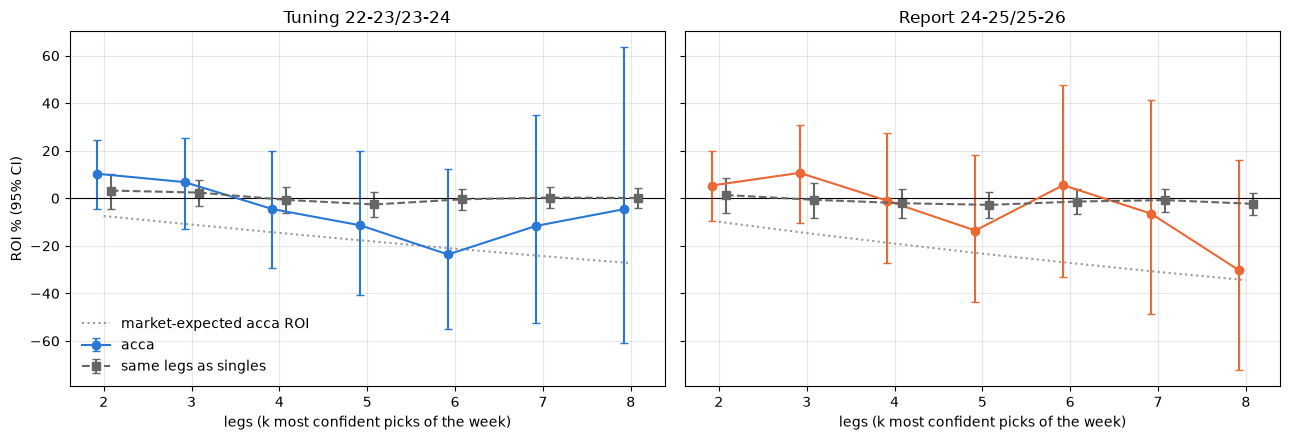

In [53]:
tk = aresults[(aresults["family"] == "acca top-k") & (aresults["source"] == "avg")].copy()
tk["k"] = tk["variant"].str.extract(r"top (\d+)")[0].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, period, colour in zip(axes, ["tune", "report"], [TUNE_COLOUR, REPORT_COLOUR]):
    d = tk[tk["period"] == period].sort_values("k")
    ax.errorbar(d["k"] - 0.08, d["roi"], yerr=[d["roi"] - d["roi_ci_low"], d["roi_ci_high"] - d["roi"]],
                fmt="o-", color=colour, capsize=3, label="acca")
    ax.errorbar(d["k"] + 0.08, d["s_roi"], yerr=[d["s_roi"] - d["s_ci_low"], d["s_ci_high"] - d["s_roi"]],
                fmt="s--", color="#666666", capsize=3, label="same legs as singles")
    ax.plot(d["k"], d["fair_roi"], ":", color="#999999", label="market-expected acca ROI")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title({"tune": "Tuning 22-23/23-24", "report": "Report 24-25/25-26"}[period])
    ax.set_xlabel("legs (k most confident picks of the week)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("ROI % (95% CI)")
axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

### Volatility and promotions

Avg odds, report seasons (and tuning for comparison). `weeks won` = share of
weeks with a bet that ended in profit. `season P(up)` = share of bootstrap
seasons (one season's worth of that period's weeks, resampled) ending in profit;
`season p5 / p95` = the 5th / 95th percentile of season profit in units.
`best wk share` = the best week's profit as a share of total profit (only when
total profit > 0; flagged if > 50%).

**Promotions (sensitivity only, not in the main result):** `b/e boost` = the
boost on acca winnings that would make the strategy break even, applied to every
multi-leg bet (`all`) or only 5+ leg bets (`5+`). `+10% 5+` = ROI with a 10%
boost on 5+ leg winnings. `refund 5+` = ROI if a 5+ leg acca that loses exactly
one leg returns the stake as cash (an upper bound); `refund fb` values the refund
as a free bet worth 70% of face, which is closer to what bookmakers give.

In [54]:
avol = run_acca(["tune", "report"], volatility=True, sources=["avg"])
vcols_vol = ["bets", "weeks_bet", "avg_legs", "roi", "s_roi", "weeks_won_pct", "longest_losing_run",
             "longest_losing_weeks", "max_drawdown", "best_week", "best_week_share",
             "season_p_up", "season_p5", "season_p95", "s_season_p_up", "s_season_p5", "s_season_p95",
             "breakeven_boost_all", "breakeven_boost_5plus", "roi_boost10_5plus", "roi_refund_5plus", "roi_refund_fb_5plus"]
vol_report = avol[avol["period"] == "report"].set_index(["family", "variant"])[vcols_vol]
flagged = avol[(avol["best_week_share"] > 50) & (avol["profit"] >= 1)]
print("Strategies where one week is more than half the profit (profit >= 1u):")
print(flagged[["family", "variant", "period", "roi", "best_week", "best_week_share"]].round(1).to_string(index=False)
      if len(flagged) else "  none")
vol_report.round(1)

Strategies where one week is more than half the profit (profit >= 1u):
               family                variant period   roi  best_week  best_week_share
acca top-k + min odds top 2 by p, odds>=1.20   tune   3.0        1.6             71.9
acca top-k + min odds top 3 by p, odds>=1.30 report   1.5        2.6            236.7
acca top-k + min odds top 4 by p, odds>=1.30   tune   4.2        4.3            137.0
acca top-k + min odds top 5 by p, odds>=1.50   tune   4.0       14.3            479.0
           acca top-k             top 6 by p report   5.5        4.9            117.8
acca top-k + min odds top 7 by p, odds>=1.20   tune  15.0       12.5            110.9
acca top-k + min odds top 7 by p, odds>=1.50   tune  66.3      123.7            248.9
acca top-k + min odds top 8 by p, odds>=1.50   tune 210.9      232.2            146.8
       acca threshold           all p>=0.700 report  25.6       13.1             70.1
       acca threshold           all p>=0.725   tune  10.5        3.2 

bets  weeks_bet  avg_legs    roi  s_roi  weeks_won_pct  longest_losing_run  longest_losing_weeks  max_drawdown  best_week  best_week_share  \
family                variant                                                                                                                                                                     
acca top-k            top 2 by p                       76         76       2.0    5.4    1.4           73.7                 3.0                   3.0           4.5        0.9             22.9   
acca top-k + min odds top 2 by p, odds>=1.20           76         76       2.0   -6.0   -3.4           55.3                 4.0                   4.0           9.8        1.3              NaN   
                      top 2 by p, odds>=1.30           76         76       2.0    7.9    3.4           55.3                 5.0                   5.0           5.0        1.5             25.7   
                      top 2 by p, odds>=1.50           76         76       2.0  -55.9  -21.1           17.1                16.0                  16.0          44.5        2.0              NaN   
acca top-k            top 3 by p                       76         76       3.0   10.7   -0.6           61.8                 4.0                   4.0           4.2        1.9             23.2   
acca top-k + min odds top 3 by p, odds>=1.20           76         76       3.0  -10.2   -3.7           39.5                 5.0                   5.0          16.1        2.1              NaN   
                      top 3 by p, odds>=1.30           76         76       3.0    1.5   -1.0           35.5                14.0                  14.0          14.0        2.6            236.7   
                      top 3 by p, odds>=1.50           76         76       3.0  -53.8  -13.5           10.5                17.0                  17.0          40.9        4.5              NaN   
acca top-k            top 4 by p                       76         76       4.0   -1.1   -2.1           43.4                 5.0                   5.0          14.2        4.1              NaN   
acca top-k + min odds top 4 by p, odds>=1.20           76         76       4.0   -6.3   -2.5           30.3                10.0                  10.0          17.1        4.1              NaN   
                      top 4 by p, odds>=1.30           76         76       4.0  -18.5   -4.1           19.7                18.0                  18.0          24.5        4.1              NaN   
                      top 4 by p, odds>=1.50           76         76       4.0  -56.1  -12.2            6.6                21.0                  21.0          42.7        6.4              NaN   
acca top-k            top 5 by p                       76         76       5.0  -13.6   -2.8           30.3                 8.0                   8.0          15.2        3.3              NaN   
acca top-k + min odds top 5 by p, odds>=1.20           76         76       5.0   -5.5   -2.1           23.7                10.0                  10.0          15.1        4.3              NaN   
                      top 5 by p, odds>=1.30           76         76       5.0  -55.3   -6.2            7.9                25.0                  25.0          43.4        6.6              NaN   
                      top 5 by p, odds>=1.50           76         76       5.0  -71.9  -13.4            2.6                30.0                  30.0          54.7       10.3              NaN   
acca top-k            top 6 by p                       76         76       6.0    5.5   -1.4           27.6                10.0                  10.0          10.8        4.9            117.8   
acca top-k + min odds top 6 by p, odds>=1.20           76         76       6.0  -14.2   -2.2           15.8                16.0                  16.0          21.5        6.3              NaN   
                      top 6 by p, odds>=1.30           76         76       6.0  -76.4   -7.2            2.6                58.0                  58.0    

### Key strategies at a glance

Avg odds. The chosen rule, the short top-k accas and the systems built on the
week's top 3-4 picks, which are the variants positive in both periods.
Promotions as above (sensitivity only).

In [55]:
KEY = [ACHOSEN, ("acca top-k", "top 2 by p"), ("acca top-k", "top 3 by p"), ("system", "Trixie, top 3 by p"),
       ("system", "Patent, top 3 by p"), ("doubles/trebles", "doubles from top 3"), ("acca top-k", "top 5 by p"),
       ("acca top-k", "top 7 by p"), ("system", "Lucky 15, top 4 by p"), ("acca P8-03 rule", "top 3 P8-03 legs")]
key_rows = []
for key in KEY:
    for period in PERIODS:
        r = acca_eval(*SETTLED[(key, "avg")], period, volatility=True)
        key_rows.append({"variant": key[1], "period": period, "bets": r["bets"], "legs": r["avg_legs"],
                         "hit %": r["hit_rate"], "acca": fmt(r) if r["bets"] else "", "singles": sfmt(r) if r["bets"] else "",
                         "diff": dfmt(r) if r["bets"] else "", "fair": r["fair_roi"], "CLV": r["clv"],
                         "b/e boost": r.get("breakeven_boost_all"), "+10% 5+": r.get("roi_boost10_5plus"),
                         "refund cash": r.get("roi_refund_5plus"), "refund fb": r.get("roi_refund_fb_5plus"),
                         "season P(up)": r.get("season_p_up"), "singles P(up)": r.get("s_season_p_up")})
pd.DataFrame(key_rows).set_index(["variant", "period"]).round(1)

bets  legs  hit %                     acca              singles                    diff  fair  CLV  b/e boost  +10% 5+  refund cash  refund fb  season P(up)  \
variant                period                                                                                                                                                                 
top 8 by p, odds>=1.50 tune      75   8.0    1.3  +210.9 [-100.0, +845.3]   -5.1 [-12.7, +2.6]  +216.0 [-98.6, +853.0] -26.5 -0.0        NaN    241.9        214.9      213.7          31.2   
                       report    76   8.0    0.0  -100.0 [-100.0, -100.0]   -9.2 [-15.8, -2.5]    -90.8 [-97.5, -84.2] -34.0 -0.1        NaN   -100.0        -96.1      -97.2           0.0   
                       26-27     11   8.0    0.0  -100.0 [-100.0, -100.0]  +4.7 [-14.9, +23.5]  -104.7 [-123.5, -85.1] -41.6  1.8        NaN   -100.0        -90.9      -93.6           0.0   
top 2 by p             tune      75   2.0   77.3      +10.3 [-4.5, +24.4]   +3.2 [-4.5, +10.3]      +7.1 [-0.8, +14.6]  -7.5 -0.1        NaN     10.3         10.3       10.3          80.1   
                       report    76   2.0   73.7       +5.4 [-9.6, +20.0]    +1.4 [-6.3, +8.5]      +4.0 [-4.3, +12.0]  -9.9 -0.7        NaN      5.4          5.4        5.4          65.6   
                       26-27     11   2.0   63.6     -14.7 [-53.7, +23.1]  -9.2 [-33.0, +11.0]     -5.5 [-28.1, +14.5] -12.4  0.8       67.8    -14.7        -14.7      -14.7          24.6   
top 3 by p             tune      75   3.0   62.7      +6.8 [-12.8, +25.4]    +2.4 [-3.4, +7.9]     +4.4 [-10.5, +18.2] -11.0 -0.0        NaN      6.8          6.8        6.8          65.3   
                       report    76   3.0   61.8     +10.7 [-10.3, +31.0]    -0.6 [-8.4, +6.3]     +11.3 [-3.6, +25.5] -14.6 -0.3        NaN     10.7         10.7       10.7          73.5   
                       26-27     11   3.0   54.5     -11.8 [-61.4, +38.1]   -7.0 [-25.4, +9.5]     -4.8 [-39.6, +29.6] -18.3  0.7       34.9    -11.8        -11.8      -11.8          33.1   
Trixie, top 3 by p     tune     300   2.2   70.3       +5.2 [-8.5, +18.3]    +2.4 [-3.4, +7.9]      +2.8 [-5.6, +10.8]  -8.4 -0.0        NaN      5.2          5.2        5.2          66.4   
                       report   304   2.2   68.1      +5.1 [-10.6, +20.0]    -0.6 [-8.4, +6.3]      +5.7 [-3.1, +14.2] -11.2 -0.3        NaN      5.1          5.1        5.1          66.2   
                       26-27     44   2.2   61.4     -12.4 [-51.0, +25.1]   -7.0 [-25.4, +9.5]     -5.4 [-27.0, +16.3] -14.0  0.7       47.2    -12.4        -12.4      -12.4          27.2   
Patent, top 3 by p     tune     525   1.7   76.8       +4.0 [-6.1, +13.7]    +2.4 [-3.4, +7.9]       +1.6 [-3.2, +6.2]  -6.4 -0.0        NaN      4.0          4.0        4.0          66.8   
                       report   532   1.7   74.1       +2.6 [-9.5, +14.2]    -0.6 [-8.4, +6.3]       +3.2 [-1.8, +8.1]  -8.6 -0.3        NaN      2.6          2.6        2.6          61.7   
                       26-27     77   1.7   68.8     -10.1 [-39.6, +18.3]   -7.0 [-25.4, +9.5]      -3.1 [-15.5, +9.3] -10.8  0.7       67.3    -10.1        -10.1      -10.1          25.7   
doubles from top 3     tune     225   2.0   72.9       +4.7 [-7.2, +16.1]    +2.4 [-3.4, +7.9]       +2.3 [-4.2, +8.4]  -7.5 -0.0        NaN      4.7          4.7        4.7          66.8   
                       report   228   2.0   70.2      +3.2 [-10.8, +16.7]    -0.6 [-8.4, +6.3]      +3.8 [-3.1, +10.5] -10.0 -0.3        NaN      3.2          3.2        3.2          62.2   
                       26-27     33   2.0   63.6     -12.6 [-47.9, +21.3]   -7.0 [-25.4, +9.5]     -5.6 [-23.3, +11.8] -12.6  0.7       53.1    -12.6        -12.6      -12.6          24.7   
top 5 by p             tune      75   5.0   30.7     -11.4 [-40.9, +19.8]    -2.6 [-8.0, +2.7]     -8.8 [-34.6, +17.8] -17.9  0.1       19.6     -5.6         31.3       18.5          29.3   
                    

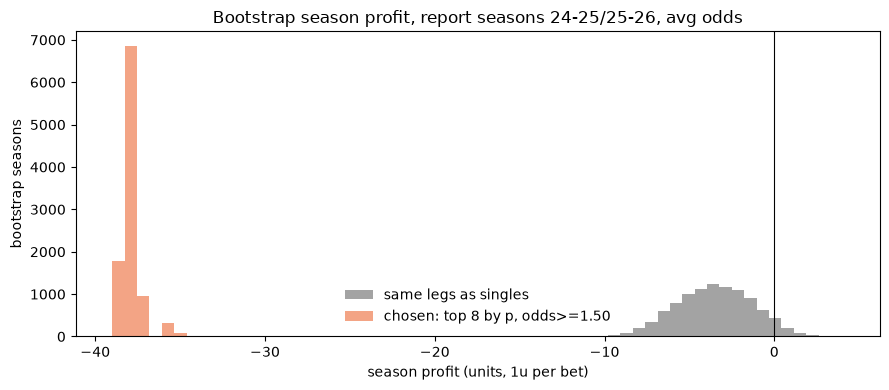

P(season in profit): acca 0.0%, singles 5.5%


In [56]:
# Season-profit bootstrap: chosen rule vs the same legs as singles, report seasons, avg
B, W = SETTLED[(ACHOSEN, "avg")]
w = W.reindex(PERIOD_WEEKS["report"], fill_value=0.0)
acca_seasons = season_profit_boot(w, "report")
single_seasons = season_profit_boot(w.assign(profit=w["s_profit"]), "report")

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(min(acca_seasons.min(), single_seasons.min()), max(acca_seasons.max(), single_seasons.max()), 60)
ax.hist(single_seasons, bins=bins, alpha=0.6, color="#666666", label="same legs as singles")
ax.hist(acca_seasons, bins=bins, alpha=0.6, color=REPORT_COLOUR, label=f"chosen: {ACHOSEN[1]}")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("season profit (units, 1u per bet)")
ax.set_ylabel("bootstrap seasons")
ax.set_title("Bootstrap season profit, report seasons 24-25/25-26, avg odds")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"P(season in profit): acca {(acca_seasons > 0).mean():.1%}, singles {(single_seasons > 0).mean():.1%}")

### Tuning vs report across all acca variants

In [57]:
awide = aresults[aresults["source"] == "avg"].pivot_table(index=["family", "variant"], columns="period",
                                                          values=["roi", "diff", "weeks_bet"])
awide = awide[(awide[("weeks_bet", "tune")] >= n_tune_weeks / 2) & (awide[("weeks_bet", "report")] >= len(PERIOD_WEEKS["report"]) / 2)]
print(f"{len(awide)} variants betting in >= half the weeks of both periods")
print(f"  ROI > 0: tuning {(awide[('roi', 'tune')] > 0).sum()}, report {(awide[('roi', 'report')] > 0).sum()}, "
      f"both {((awide[('roi', 'tune')] > 0) & (awide[('roi', 'report')] > 0)).sum()}")
print(f"  beat same-leg singles: tuning {(awide[('diff', 'tune')] > 0).sum()}, report {(awide[('diff', 'report')] > 0).sum()}, "
      f"both {((awide[('diff', 'tune')] > 0) & (awide[('diff', 'report')] > 0)).sum()}")
print(f"  tuning vs report ROI correlation {awide[('roi', 'tune')].corr(awide[('roi', 'report')]):+.2f}")

64 variants betting in >= half the weeks of both periods
  ROI > 0: tuning 17, report 14, both 8
  beat same-leg singles: tuning 18, report 18, both 9
  tuning vs report ROI correlation +0.22


## P8-05 variant log

In [58]:
log = log_variants(aresults.drop(columns=[c for c in aresults.columns if c not in
                                         ["family", "variant", "source", "period", "bets", "bets_per_week",
                                          "hit_rate", "avg_odds", "roi", "roi_ci_low", "roi_ci_high", "clv"]]),
                   ticket="P8-05")
print(f"Logged {aresults.groupby(['family', 'variant']).ngroups} P8-05 variants; log now holds",
      log.groupby("ticket")["variant"].nunique().to_dict())

Logged 67 P8-05 variants; log now holds {'P8-03': 274, 'P8-04': 331, 'P8-05': 67, 'P8-06': 134}


In [59]:
# For P8-07: weekly P&L of every P8-05 variant and the chosen rule's accas (one row per acca)
weekly, bets = [], []
for (key, source), (B, W) in SETTLED.items():
    weekly.append(W.reset_index()[["Week", "profit", "staked"]].assign(family=key[0], variant=key[1], source=source))
    if key == ACHOSEN:
        bets.append(pd.DataFrame({
            "rule": key[1], "source": source, "Season": B["Week"].map(SEASON_OF_WEEK), "Week": B["Week"],
            "Div": "multi", "MatchKey": "", "selection": B["legs"].astype(str) + " legs", "odds": B["odds"],
            "stake": B["stake"], "profit": B["profit"], "clv": B["clv_sum"] / B["clv_n"].replace(0, np.nan),
        }))
weekly = pd.concat(weekly, ignore_index=True)
check_totals(weekly, aresults)
log_variant_weeks(weekly, ticket="P8-05")
log_chosen_bets(pd.concat(bets, ignore_index=True), ticket="P8-05")
print(f"Weekly P&L logged for {weekly.groupby(['family', 'variant']).ngroups} variants; chosen-rule accas:",
      pd.concat(bets).groupby("source").size().to_dict())

Weekly P&L logged for 66 variants; chosen-rule accas: {'avg': 162, 'b365': 162, 'max': 162}


## P8-05 findings

**Verdict: accumulators don't make money, and they don't beat singles on the same
legs.** The legs have no edge (P8-03/P8-04), so an acca just compounds the margin.
What it adds is variance. The pre-registered rule picked a lottery ticket that won
once in tuning and never since.

- **Chosen rule (pre-registered):** acca of the week's 8 most confident picks with
  odds >= 1.50. Tuning **+210.9%** [-100, +845] at avg. That was **1 winning acca out of 75**
  (at ~102), which is all of the profit. **Report -100%** (0 of 76), 26-27 -100%
  (0 of 11). The same legs as singles: -5.1% tune, -9.2% report. The market expected
  -26% / -34% from the compounded margin. Of 64 eligible tuning variants, 17 were
  positive and 18 beat their singles. With accas, "highest tuning ROI" mostly rewards
  whichever long acca happened to land, so the selection rule is especially exposed
  to luck here.
- **Legs are independent:** standardised residual correlation between same-week
  picks is -0.001 [-0.004, +0.003] across leagues and +0.004 [-0.011, +0.019] for same
  league, same day. So the acca prices aren't wrong for correlation reasons, and
  E[acca] ~ product of the legs' E[return].
- **Compounded margin** (market-expected acca ROI, report, avg): 2 legs -10%,
  3 legs -15%, 5 legs -23%, 7 legs -31% (the chosen 8-leg rule: -34%). Threshold accas (p >= 0.55..0.65,
  12-28 legs) almost never win: -80% to -100% in every period.
- **Short favourite accas are the closest thing to a result, and it's noise.** Top-2 /
  top-3 accas of the most confident picks (odds ~1.2-1.3 a leg) were positive in
  both periods: top 2 +10.3 / +5.4 [-9.6, +20.0], top 3 +6.8 / +10.7 [-10.3, +31.0]
  (tune / report, avg). Trixie, Patent and doubles from the top 3 were the same
  (+2.6..+5.7 report). But the same legs as singles were +2.4 / -0.6, so the legs have
  ~0 edge. The acca-minus-singles CI crosses 0 in both periods at avg (at max, top 3 report is
  +16.6 [+0.5, +32.1], the optimistic bound), CLV is
  slightly negative (-0.3, -0.7), 26-27 is -12..-15%, and with independent legs an
  acca of ~0-edge legs has ~0 expected ROI. This is the favourite-longshot pattern P8-02
  already found (short favourites lose the least), not skill. Accas of 4+ legs lose more
  than singles.
- **Value accas** (P8-04 legs, top-k by edge): -21% to -30% report vs singles -0.5 to
  -3%, and they barely bet without Pinnacle prices (26-27). **P8-03-rule accas** (P1
  picks): top 3 +21 / +10 / +53 on 66 / 68 / 10 bets, but singles +5.5 / +1.3, and the
  P8-03 rule itself failed its report test (-5.5%). Not evidence.
- **Systems vs singles:** the more singles a system holds, the closer it tracks them.
  Patent (3 singles + 4 multiples) diff +1.6 / +3.2, Lucky 15 -0.7 / -0.1. Systems on
  4+ legs and value-leg systems lose more than singles.
- **Volatility (report, avg):** a top-3 acca wins 62% of weeks, top 5 30%, top 7 20%,
  top 8 at odds >= 1.50 never. Longest losing runs grow from 3-4 weeks (2-3 legs) to
  16-17 (7-8 legs) and 52-76 for the long-odds variants. In 15 variant x period cells
  a single week was more than half the profit.
- **Overfitting check:** 64 variants bet in at least half the weeks of both periods.
  ROI > 0: 17 tune, 14 report, 8 both. Beat same-leg singles: 18 / 18 / 9. Tuning vs
  report ROI correlation +0.22.

**Promotions (sensitivity only):**
- **Acca boosts:** a typical +10% at 5+ legs adds a few points at most. It lifts a few
  near-zero variants just over 0 in report (e.g. p >= 0.725 acca -0.8 to +1.1), nothing robust. Break-even boosts on winnings, report: top 5 acca 24%, top 7 9%, threshold
  accas 40% to 900%+.
- **"One leg lets you down" refunds are the exception.** On 5-7 leg accas of the most
  confident picks, losing exactly one leg is the most likely way to lose, so a refund
  on 5+ legs is worth a lot. With a cash refund, top 5 is +31% tune / +30% report
  (-2% 26-27). As a free bet worth 70%: +19% / +17% / -24%. That's promotion value,
  not model skill (it would work with any short-priced legs), and real offers cap
  the refund (often £10-£25), set minimum leg odds, and get accounts restricted. Out
  of scope for P8-07, but it is the only positive-expectation thing in this ticket.

**For P8-07:** P8-05's entry is the pre-registered rule (top 8 by p, odds >= 1.50:
-100% report). 67 P8-05 variants logged, 672 in total. Accas are deterministic
combinations of P8-03 legs, so they're strongly dependent on P8-03's variants.
